In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, train_test_split, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.base import clone

from itertools import combinations

from scipy.special import ndtr

from pathlib import Path

In [4]:
file_path = Path("data") / "train.csv"

train = pd.read_csv(file_path)
train

,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,JobTenure,EmploymentStatus,EducationLevel,Experience,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,RiskScore
0,2010-06-26,27.0,66829.0,549.0,17290.0,60.0,Divorced,1.0,Rent,1095.0,...,4.0,Employed,Associate,4.0,35067.0,0.257790,0.251465,508.970230,0.288013,66.176500
1,1996-09-23,55.0,172147.0,850.0,16110.0,36.0,Widowed,1.0,Mortgage,211.0,...,2.0,Employed,High School,33.0,27001.0,0.086110,0.093173,514.675859,0.050585,28.495737
2,2015-01-19,51.0,300000.0,850.0,38436.0,36.0,Married,0.0,Mortgage,546.0,...,3.0,Employed,Bachelor,28.0,278382.0,0.108436,0.115443,1268.276385,0.072571,34.488104
3,1981-05-12,25.0,34683.0,847.0,19186.0,48.0,Married,0.0,Other,153.0,...,3.0,Employed,High School,0.0,9224.0,0.100686,0.112822,498.505187,0.225415,36.910753
4,1995-05-07,55.0,300000.0,850.0,30437.0,48.0,Single,2.0,Rent,562.0,...,5.0,Employed,Bachelor,31.0,4502.0,0.110437,0.089037,756.035156,0.052721,31.347091
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11012,2010-07-10,57.0,300000.0,850.0,14756.0,48.0,Married,2.0,Own,620.0,...,4.0,Employed,Associate,38.0,167544.0,0.094756,0.106387,378.792448,0.039952,32.440586
11013,2003-10-22,28.0,15000.0,300.0,51361.0,96.0,Single,1.0,Own,696.0,...,3.0,Employed,Bachelor,5.0,116879.0,0.446361,0.401087,1793.042130,1.991234,67.673170
11014,1983-05-12,23.0,15000.0,302.0,30724.0,72.0,Married,3.0,Rent,413.0,...,3.0,Self-Employed,Associate,0.0,250778.0,0.404724,0.360670,1047.672294,1.168538,75.292707
11015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# EDA

In [5]:
missing = train.isnull().sum()
missing_table = pd.DataFrame({'Missing Values': missing, 'Percentage': (missing / len(train)) * 100})
missing_table = missing_table[missing_table['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

missing_table 

,Missing Values,Percentage
MonthlyDebtPayments,1031,9.358265
LoanAmount,1031,9.358265
CreditScore,1031,9.358265
BaseInterestRate,1031,9.358265
NetWorth,1031,9.358265
TotalAssets,1031,9.358265
BankruptcyHistory,1031,9.358265
LoanPurpose,1031,9.358265
CheckingAccountBalance,1031,9.358265
ApplicationDate,530,4.810747


In [6]:
duplicates = train.duplicated().sum()
duplicates

np.int64(1016)

In [7]:
train['RiskScore'].describe()

count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64

In [8]:
train['RiskScore'].isnull().sum()

np.int64(530)

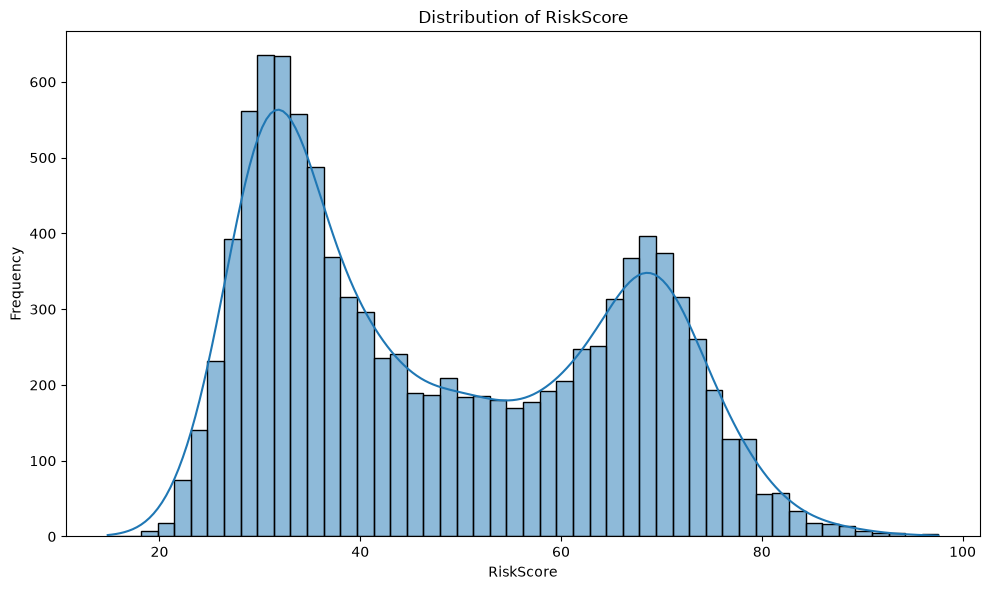

In [9]:
cropped_train = train.loc[train['RiskScore'].between(0, 100)].copy()

plt.figure(figsize=(10, 6))

sns.histplot(cropped_train['RiskScore'], bins=50, kde=True)

plt.title('Distribution of RiskScore')
plt.xlabel('RiskScore')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

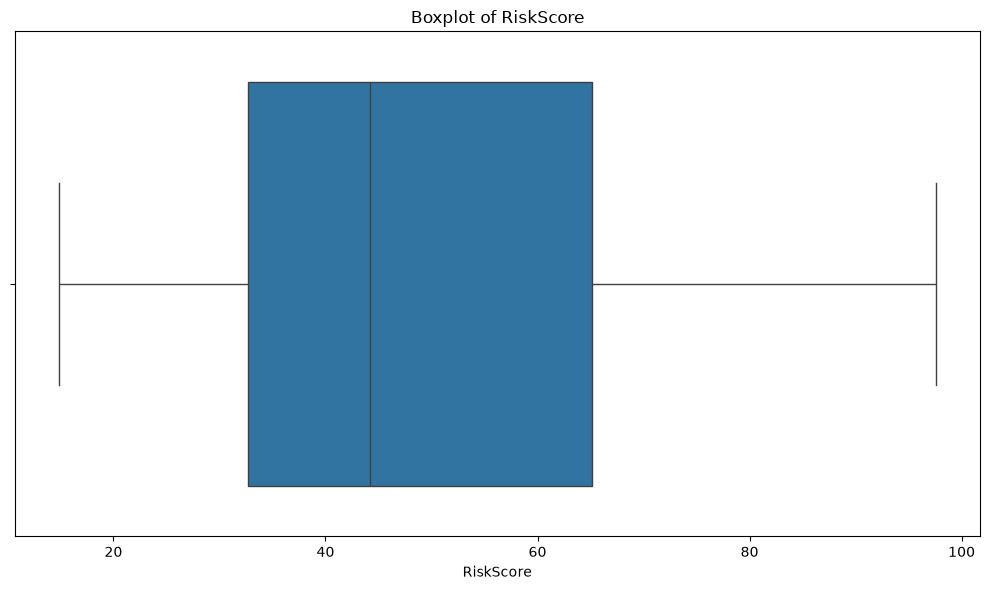

In [10]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=cropped_train['RiskScore'])

plt.title('Boxplot of RiskScore')
plt.xlabel('RiskScore')
plt.tight_layout()
plt.show()

In [11]:
numeric_columns = train.select_dtypes(include=[np.number]).columns.tolist()
numeric_columns

['Age',
 'AnnualIncome',
 'CreditScore',
 'LoanAmount',
 'LoanDuration',
 'NumberOfDependents',
 'MonthlyDebtPayments',
 'CreditCardUtilizationRate',
 'NumberOfOpenCreditLines',
 'NumberOfCreditInquiries',
 'DebtToIncomeRatio',
 'BankruptcyHistory',
 'PreviousLoanDefaults',
 'PaymentHistory',
 'LengthOfCreditHistory',
 'SavingsAccountBalance',
 'CheckingAccountBalance',
 'TotalAssets',
 'TotalLiabilities',
 'MonthlyIncome',
 'UtilityBillsPaymentHistory',
 'JobTenure',
 'Experience',
 'NetWorth',
 'BaseInterestRate',
 'InterestRate',
 'MonthlyLoanPayment',
 'TotalDebtToIncomeRatio',
 'RiskScore']

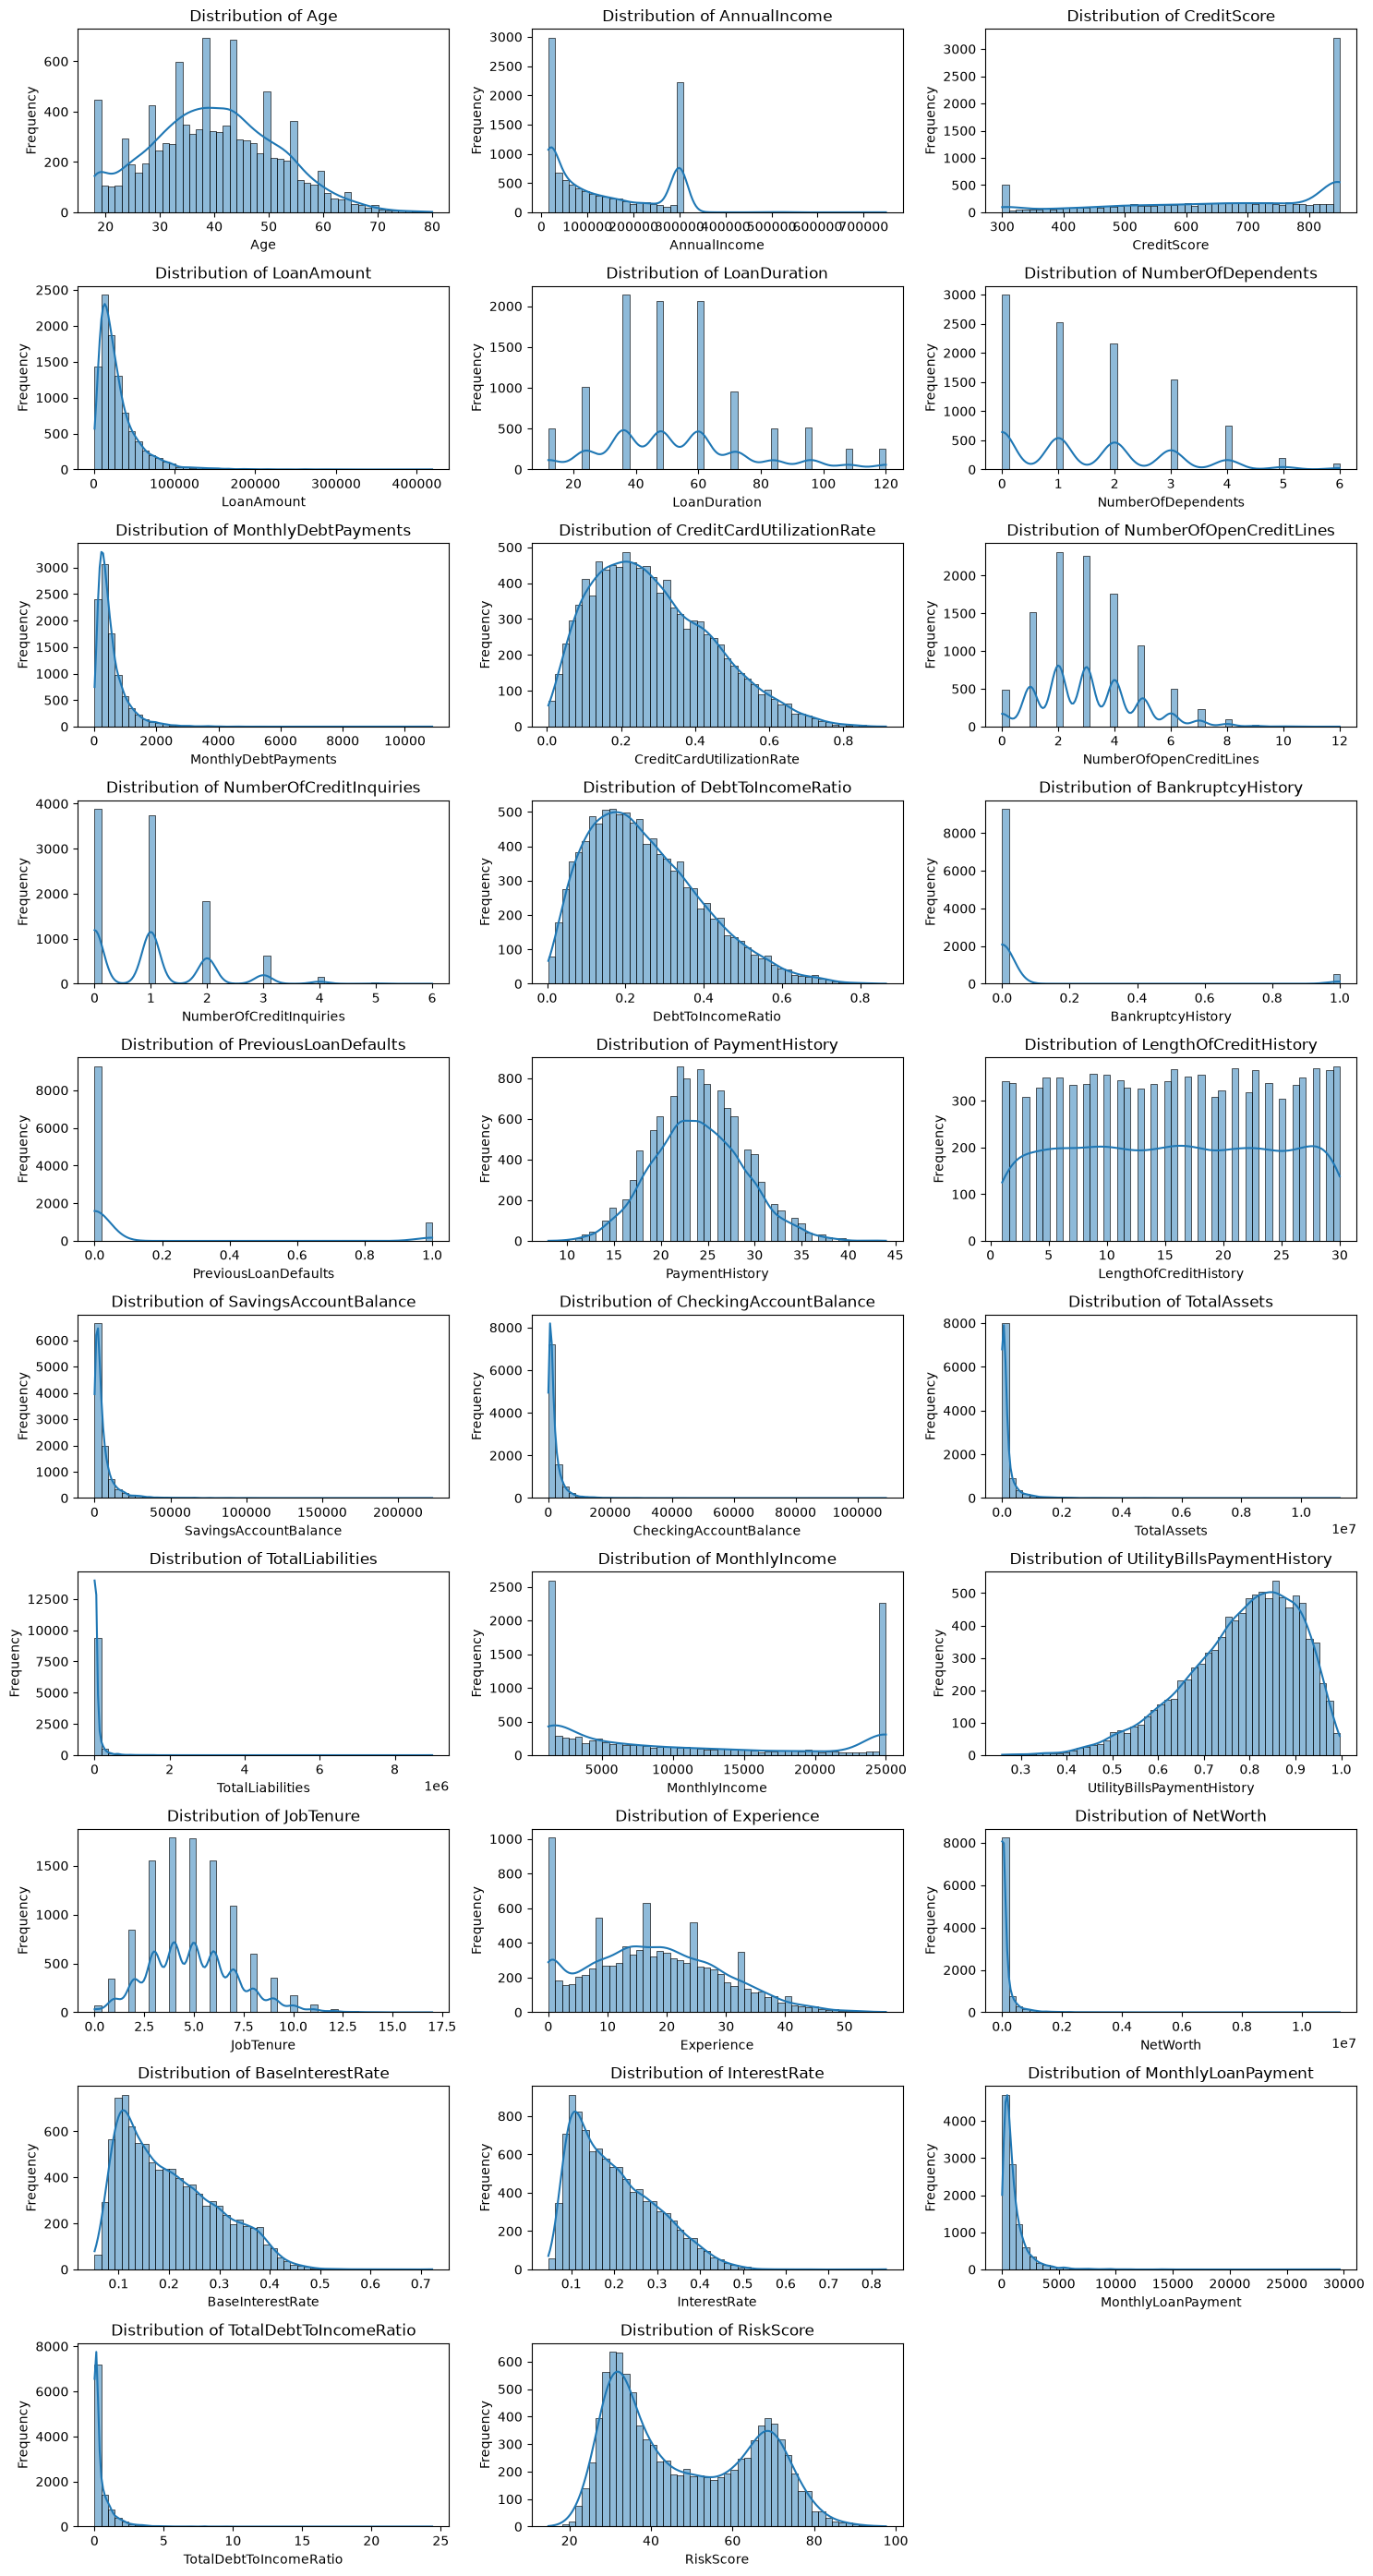

In [12]:
fig, axes = plt.subplots(10, 3, figsize=(15, 28))

for feature, ax in zip(numeric_columns, axes.flatten()):
    sns.histplot(cropped_train[feature].dropna(), bins=50, kde=True, ax=ax)

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')

for ax in axes.flatten()[len(numeric_columns):]:
    ax.set_visible(False)
    
plt.tight_layout()
plt.show()

In [13]:
categorical_columns = train.select_dtypes(include=[object, str]).columns.tolist()
categorical_columns

['ApplicationDate',
 'MaritalStatus',
 'HomeOwnershipStatus',
 'LoanPurpose',
 'EmploymentStatus',
 'EducationLevel']

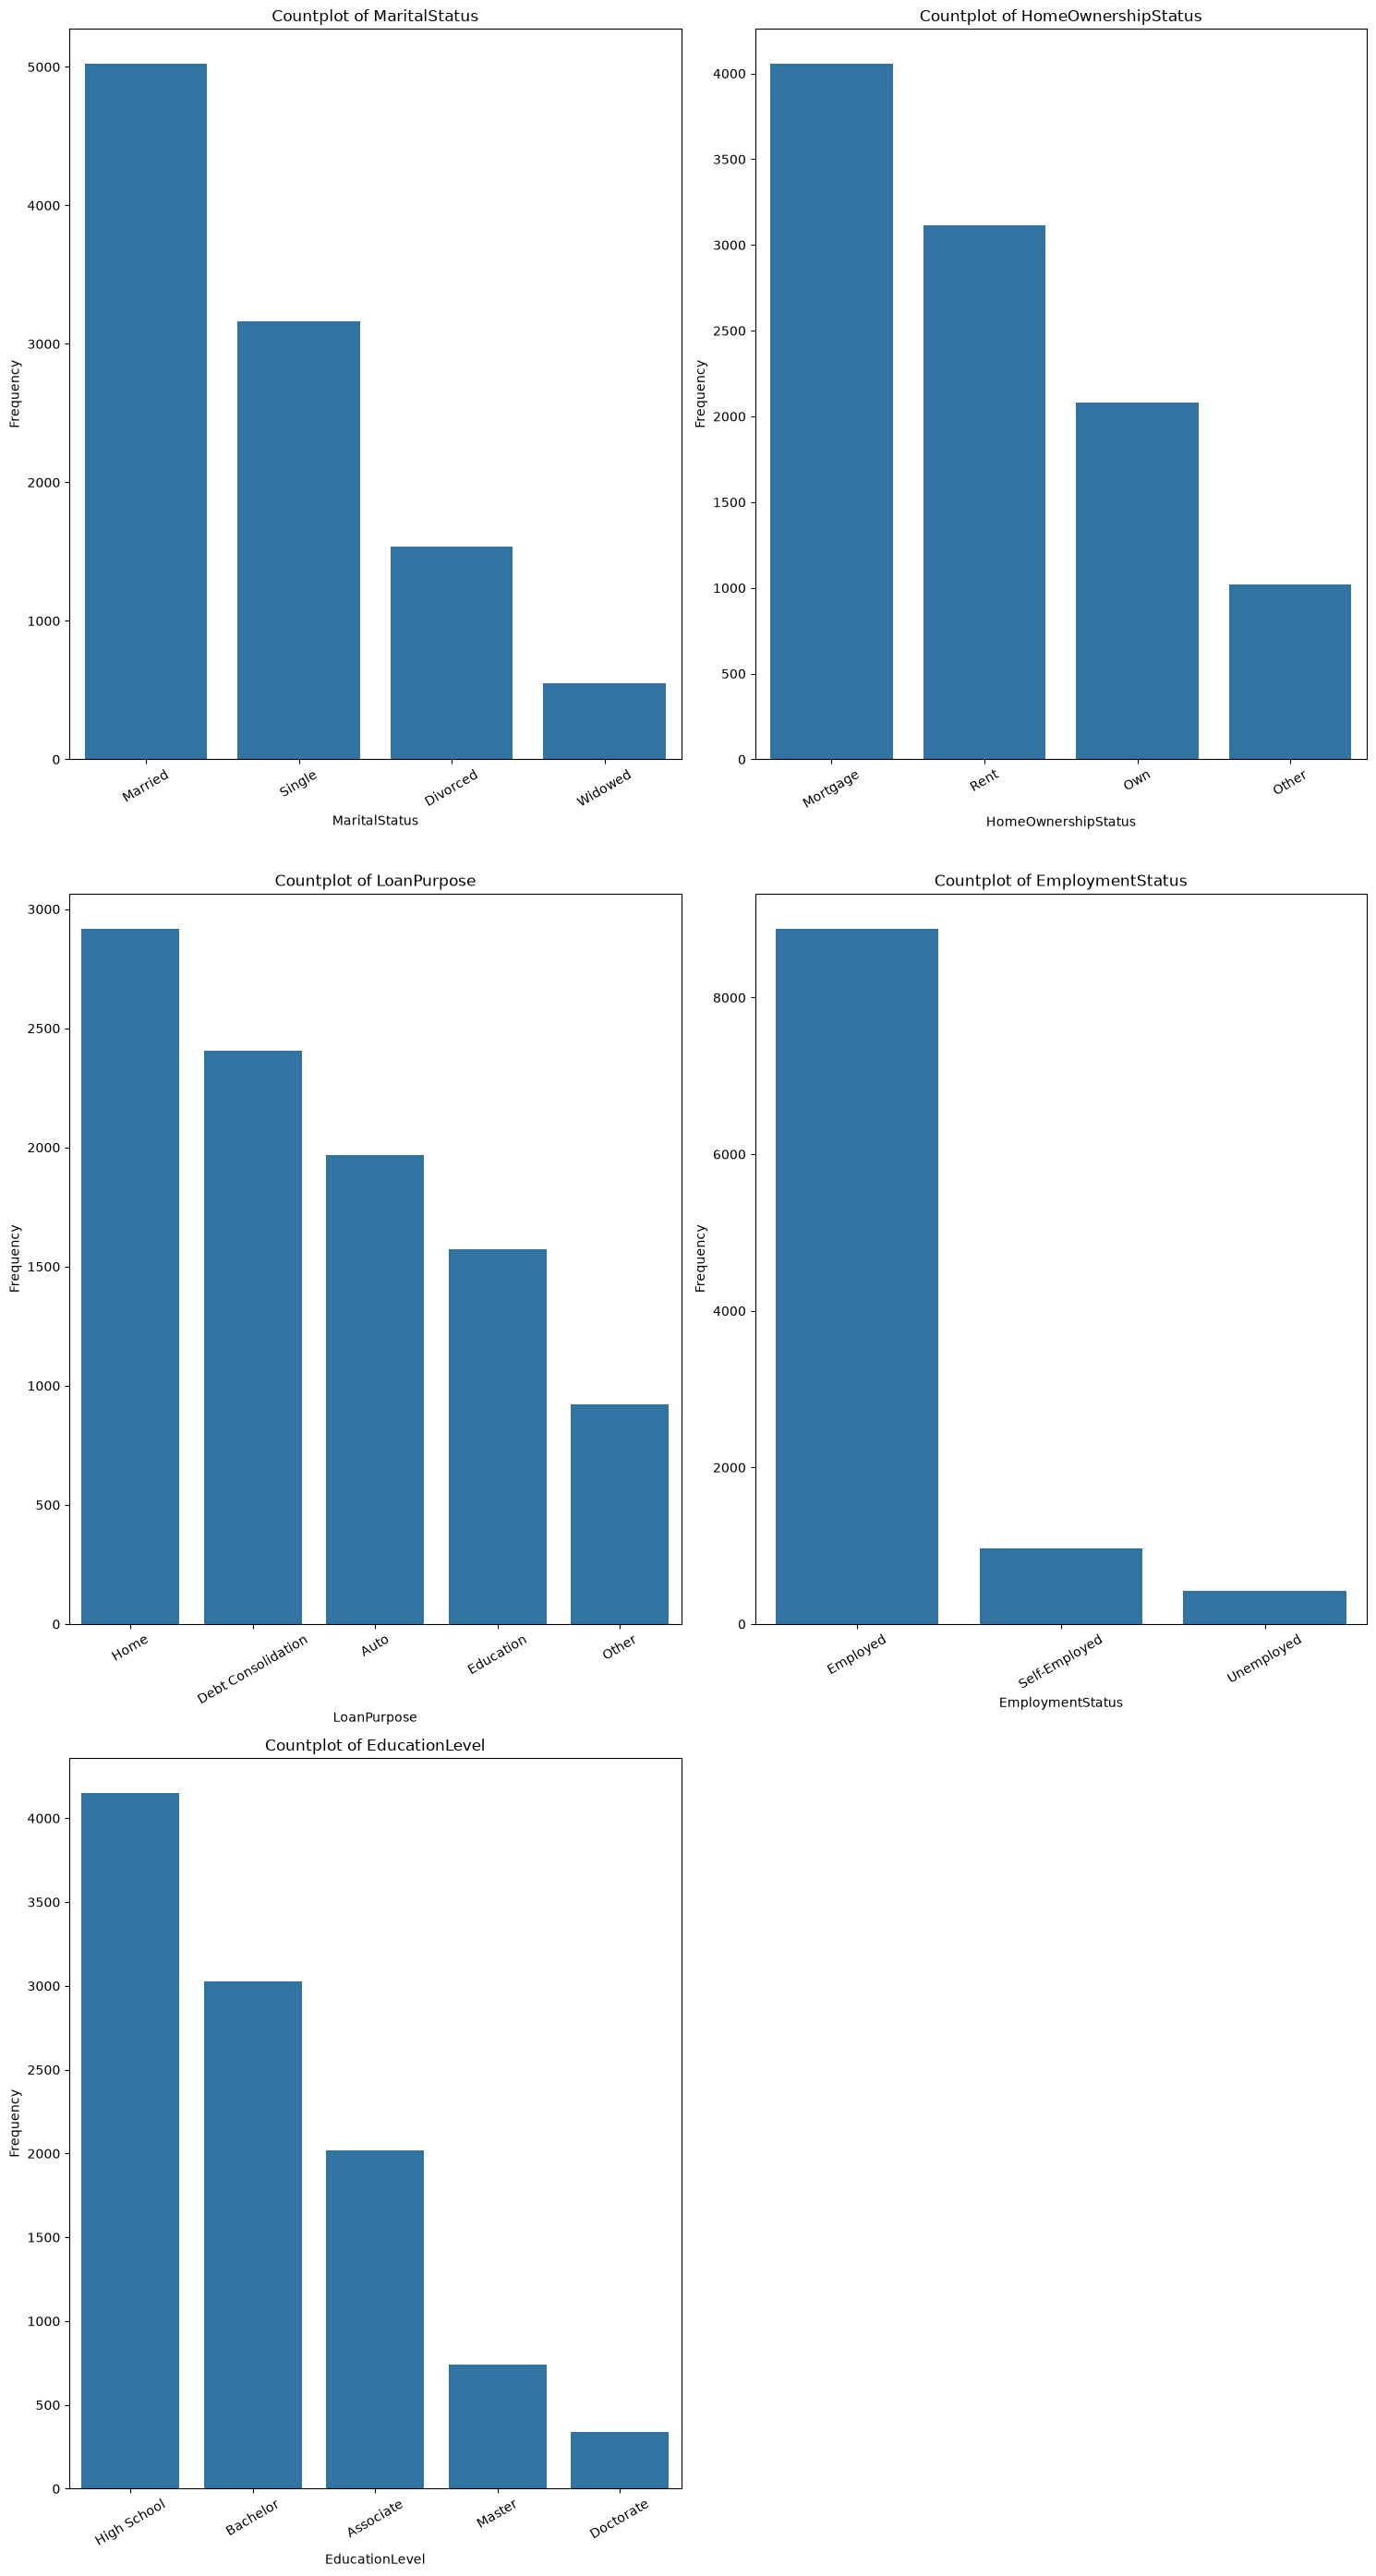

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(15, 28))

for feature, ax in zip([col for col in categorical_columns if col != 'ApplicationDate'], axes.flatten()):
    sns.countplot(x=feature, data=cropped_train, order=cropped_train[feature].value_counts().index, ax=ax)

    ax.set_title(f'Countplot of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')
    ax.tick_params(axis='x', rotation=30)

for ax in axes.flatten()[len(categorical_columns)-1:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

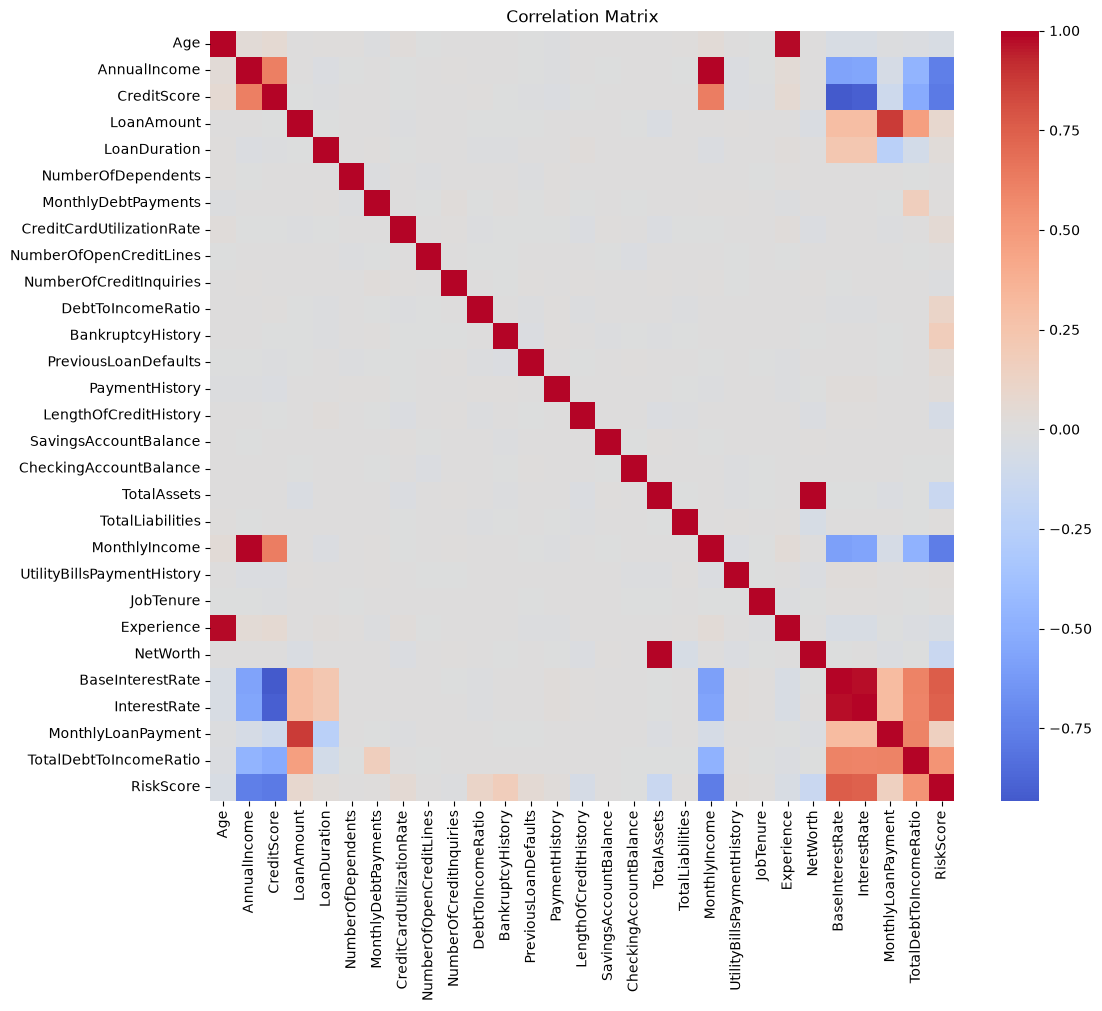

In [15]:
correlation_matrix = cropped_train[numeric_columns].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', center=0)

plt.title('Correlation Matrix')
plt.show()

In [16]:
corr_upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
corr_pairs = corr_upper_triangle.stack().reset_index()
corr_pairs.columns = ['Feature1', 'Feature2', 'Correlation']

strong_corr = corr_pairs[(corr_pairs['Correlation'] > 0.7) | (corr_pairs['Correlation'] < -0.7)]
strong_corr

,Feature1,Feature2,Correlation
22,Age,Experience,0.982964
48,AnnualIncome,MonthlyIncome,0.985438
57,AnnualIncome,RiskScore,-0.758514
82,CreditScore,BaseInterestRate,-0.931577
83,CreditScore,InterestRate,-0.907192
86,CreditScore,RiskScore,-0.785425
113,LoanAmount,MonthlyLoanPayment,0.872616
516,TotalAssets,NetWorth,0.993996
579,MonthlyIncome,RiskScore,-0.770267
721,BaseInterestRate,InterestRate,0.975344


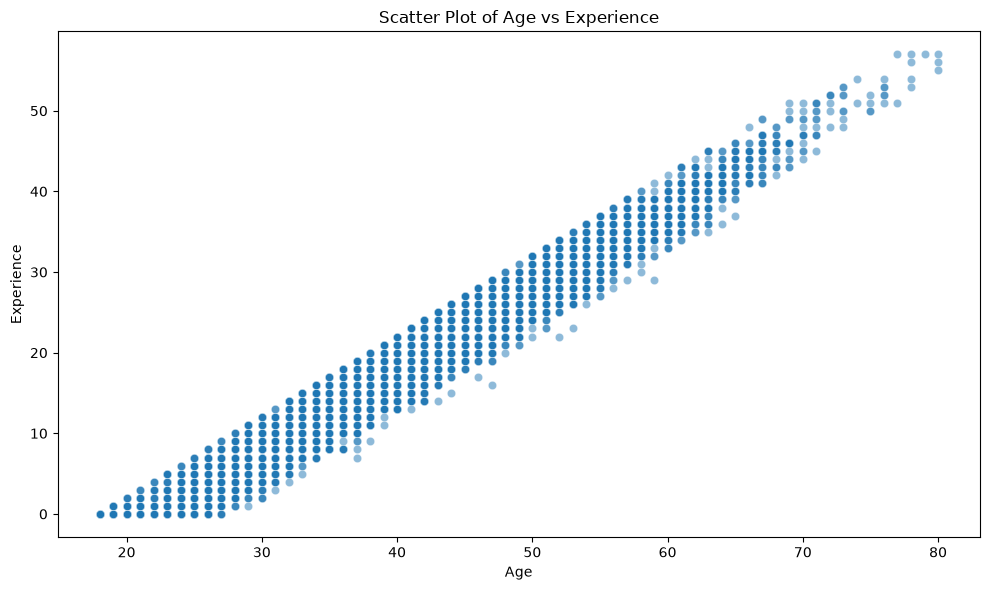

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='Age', y='Experience', alpha=0.5)

plt.title('Scatter Plot of Age vs Experience')
plt.xlabel('Age')
plt.ylabel('Experience')
plt.tight_layout()
plt.show()

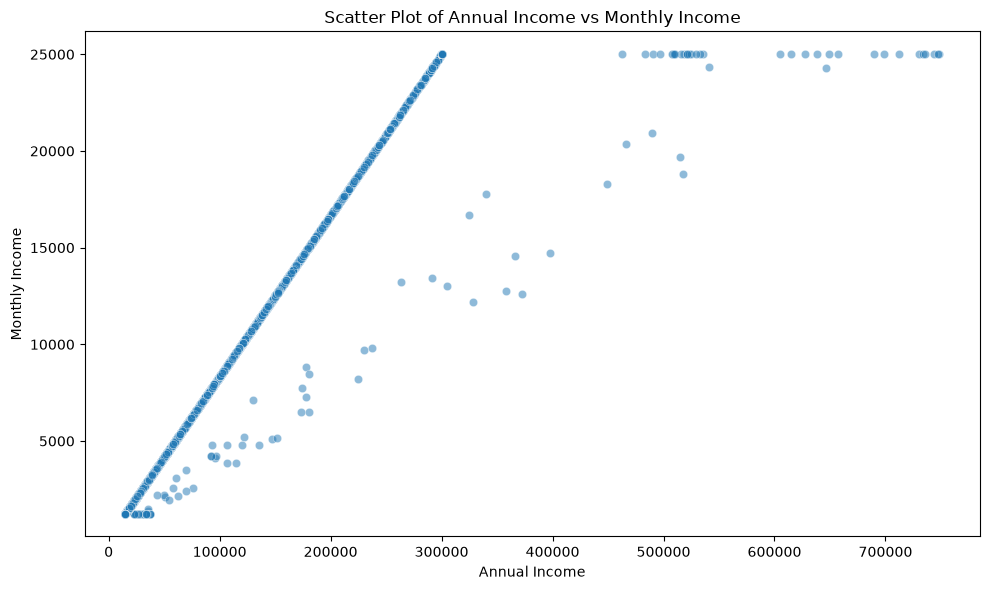

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='AnnualIncome', y='MonthlyIncome', alpha=0.5)

plt.title('Scatter Plot of Annual Income vs Monthly Income')
plt.xlabel('Annual Income')
plt.ylabel('Monthly Income')
plt.tight_layout()
plt.show()

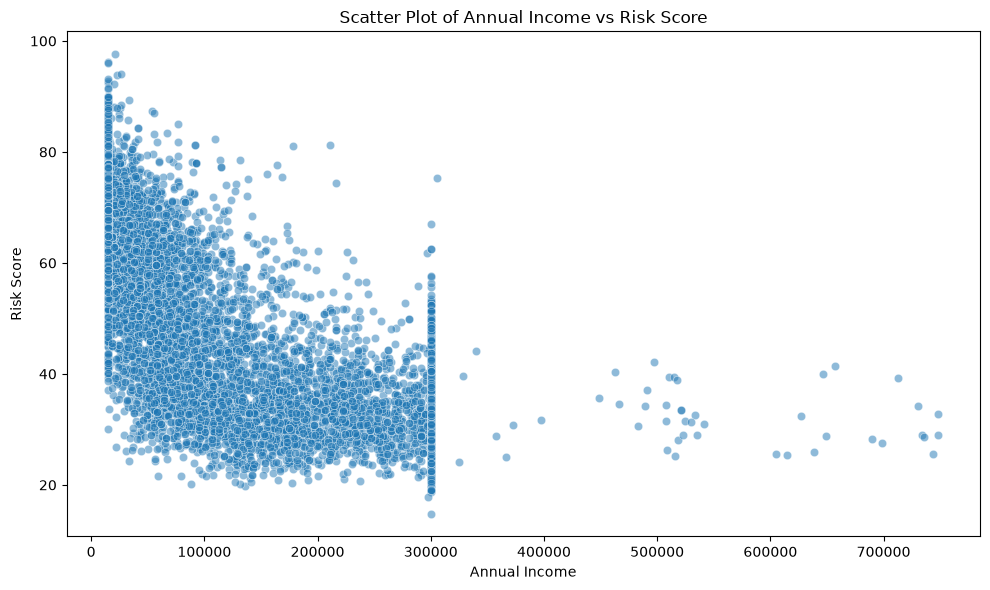

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='AnnualIncome', y='RiskScore', alpha=0.5)

plt.title('Scatter Plot of Annual Income vs Risk Score')
plt.xlabel('Annual Income')
plt.ylabel('Risk Score')
plt.tight_layout()
plt.show()

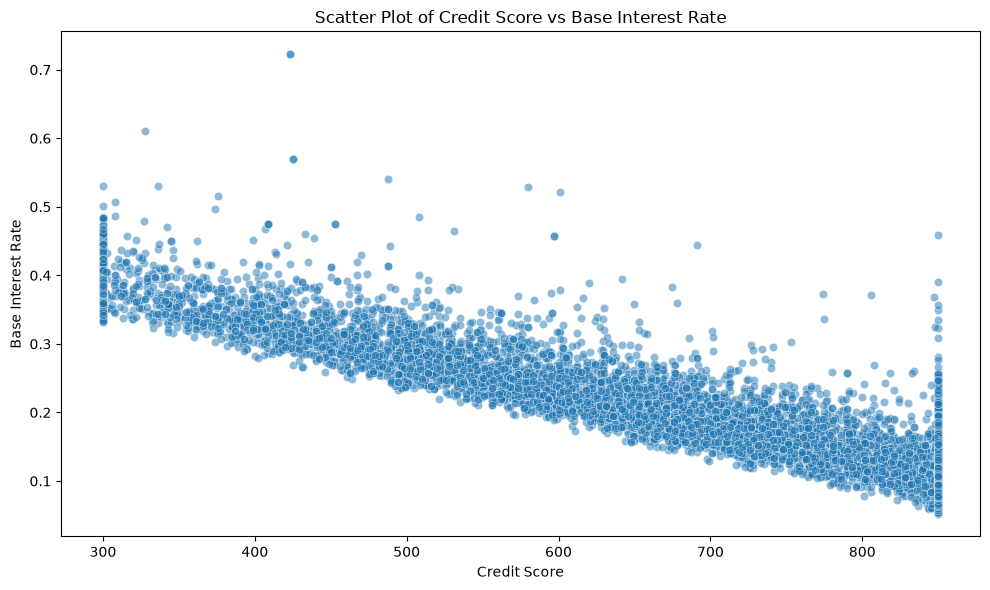

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='CreditScore', y='BaseInterestRate', alpha=0.5)

plt.title('Scatter Plot of Credit Score vs Base Interest Rate')
plt.xlabel('Credit Score')
plt.ylabel('Base Interest Rate')
plt.tight_layout()
plt.show()

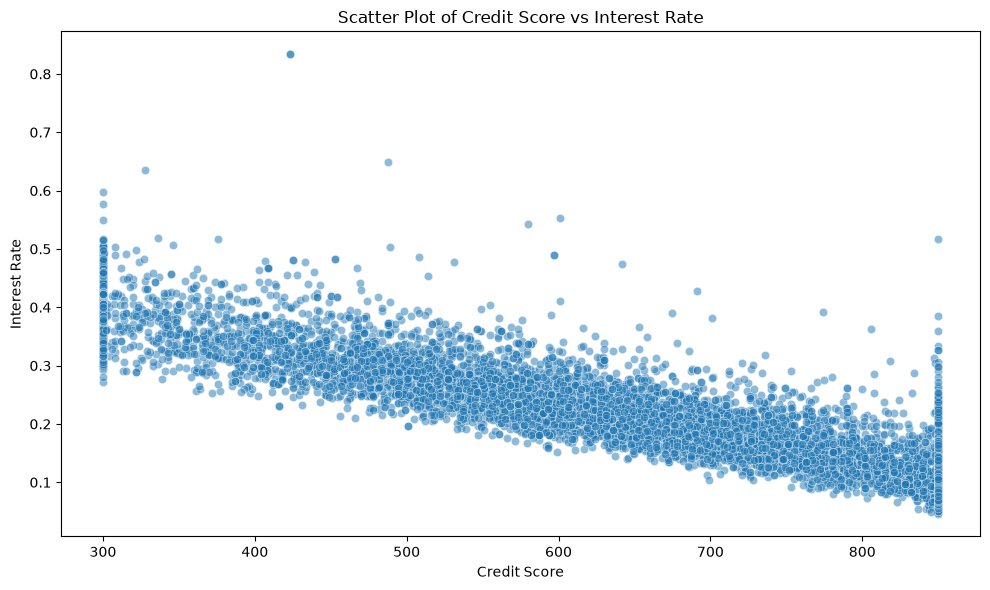

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='CreditScore', y='InterestRate', alpha=0.5)

plt.title('Scatter Plot of Credit Score vs Interest Rate')
plt.xlabel('Credit Score')
plt.ylabel('Interest Rate')
plt.tight_layout()
plt.show()

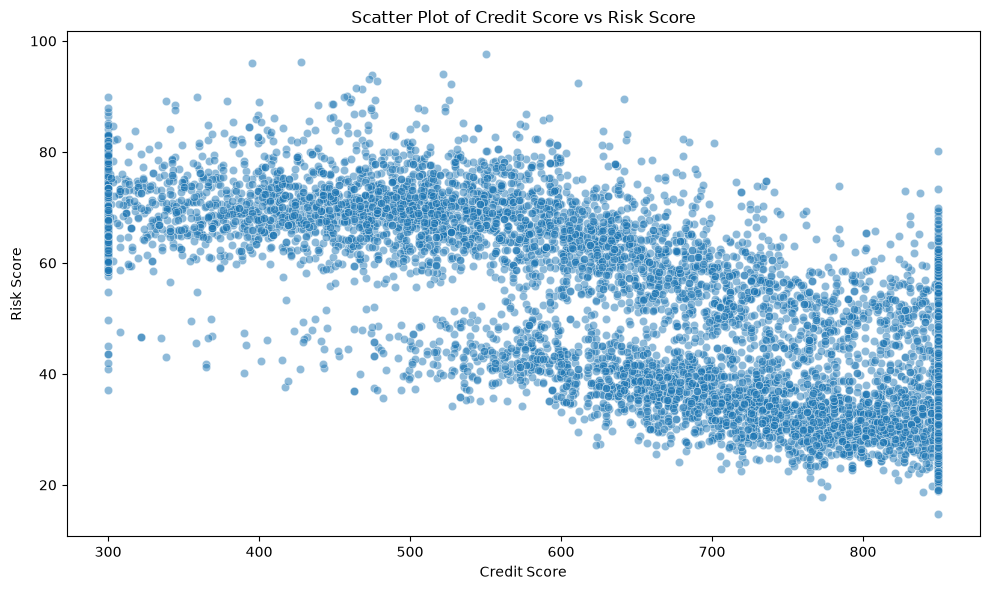

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='CreditScore', y='RiskScore', alpha=0.5)

plt.title('Scatter Plot of Credit Score vs Risk Score')
plt.xlabel('Credit Score')
plt.ylabel('Risk Score')
plt.tight_layout()
plt.show()

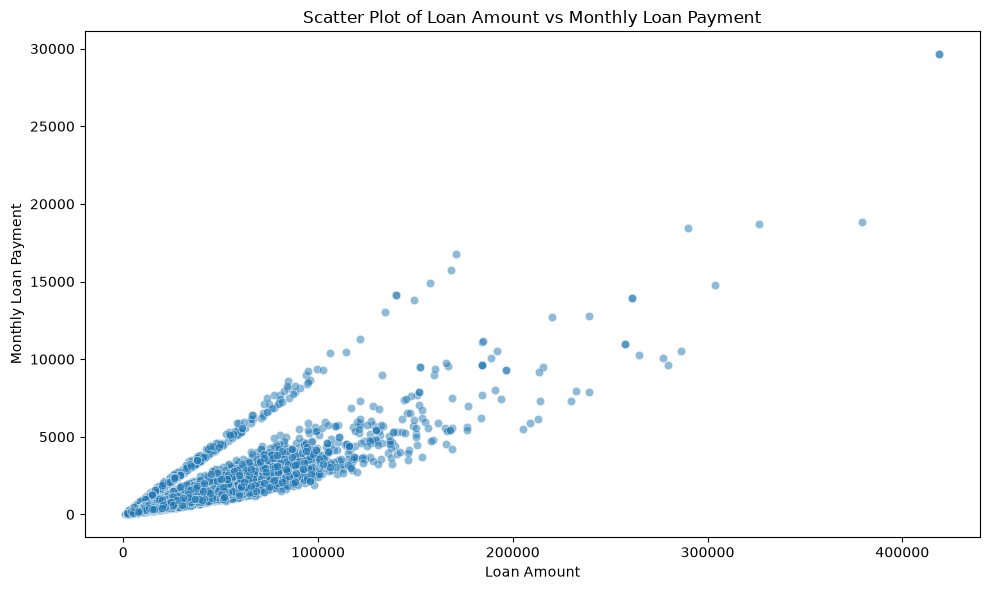

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='LoanAmount', y='MonthlyLoanPayment', alpha=0.5)

plt.title('Scatter Plot of Loan Amount vs Monthly Loan Payment')
plt.xlabel('Loan Amount')
plt.ylabel('Monthly Loan Payment')
plt.tight_layout()
plt.show()

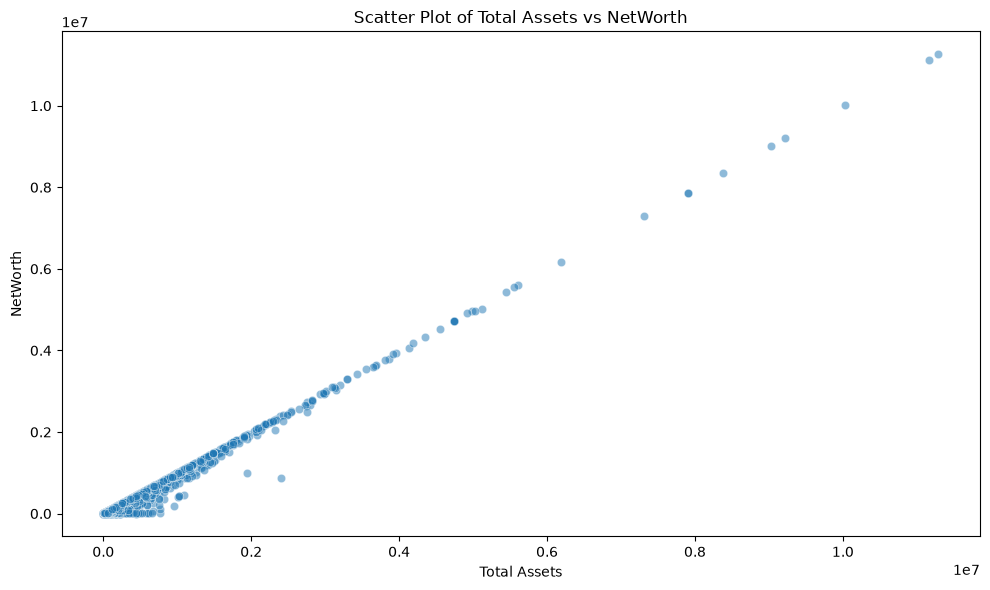

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='TotalAssets', y='NetWorth', alpha=0.5)

plt.title('Scatter Plot of Total Assets vs NetWorth')
plt.xlabel('Total Assets')
plt.ylabel('NetWorth')
plt.tight_layout()
plt.show()

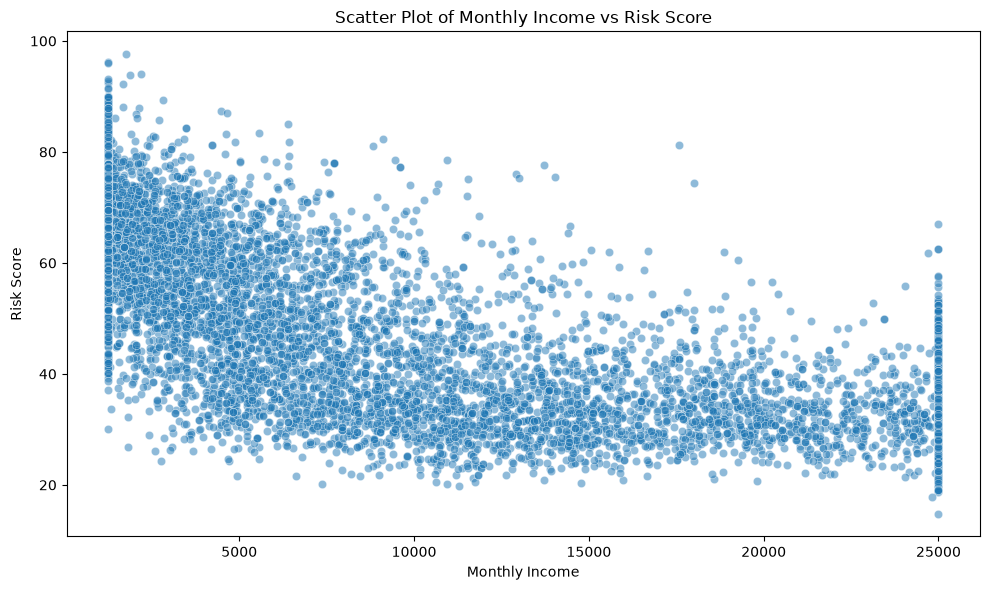

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='MonthlyIncome', y='RiskScore', alpha=0.5)

plt.title('Scatter Plot of Monthly Income vs Risk Score')
plt.xlabel('Monthly Income')
plt.ylabel('Risk Score')
plt.tight_layout()
plt.show()

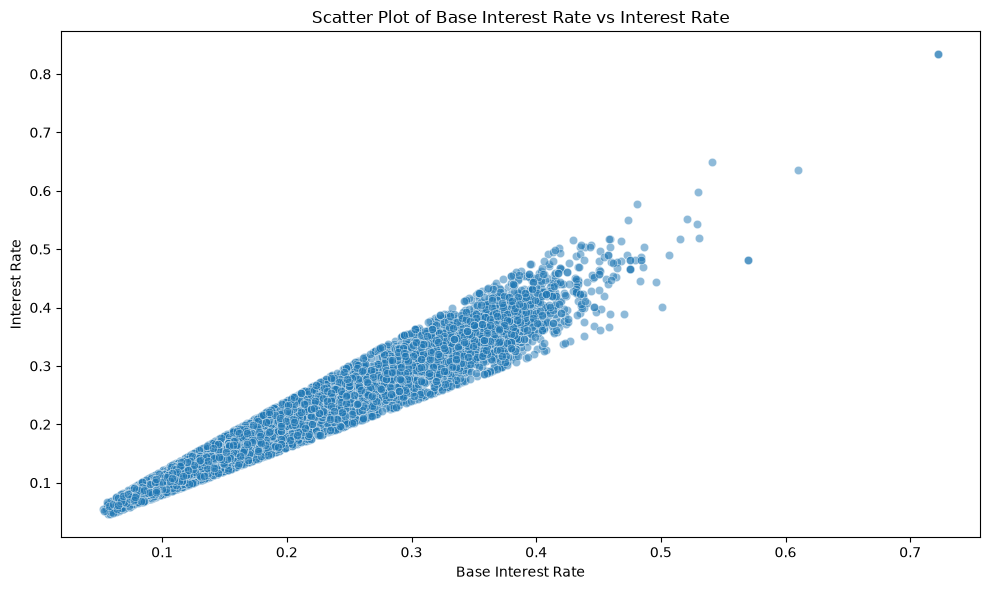

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='BaseInterestRate', y='InterestRate', alpha=0.5)

plt.title('Scatter Plot of Base Interest Rate vs Interest Rate')
plt.xlabel('Base Interest Rate')
plt.ylabel('Interest Rate')
plt.tight_layout()
plt.show()

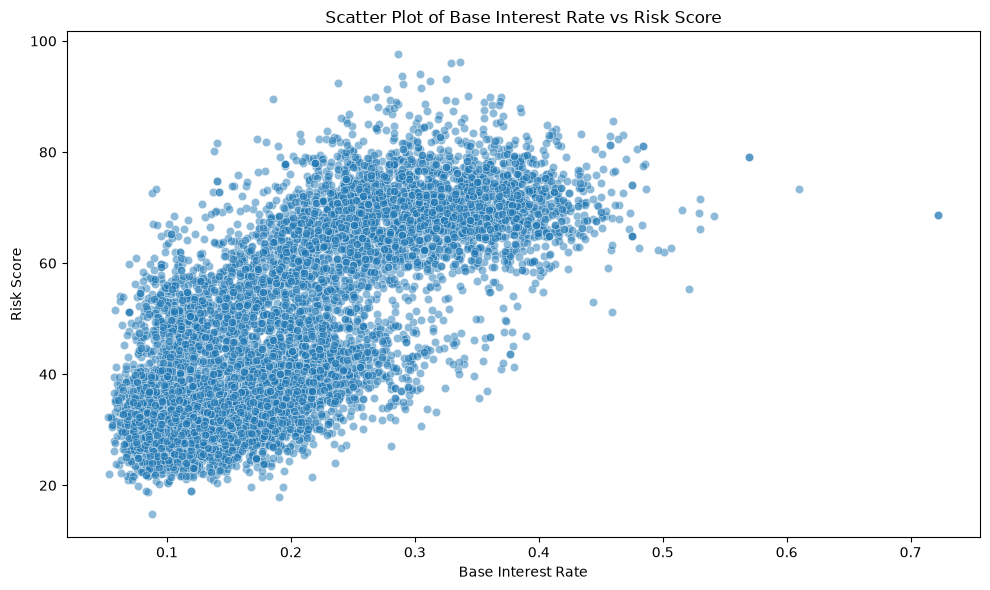

In [27]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='BaseInterestRate', y='RiskScore', alpha=0.5)

plt.title('Scatter Plot of Base Interest Rate vs Risk Score')
plt.xlabel('Base Interest Rate')
plt.ylabel('Risk Score')
plt.tight_layout()
plt.show()

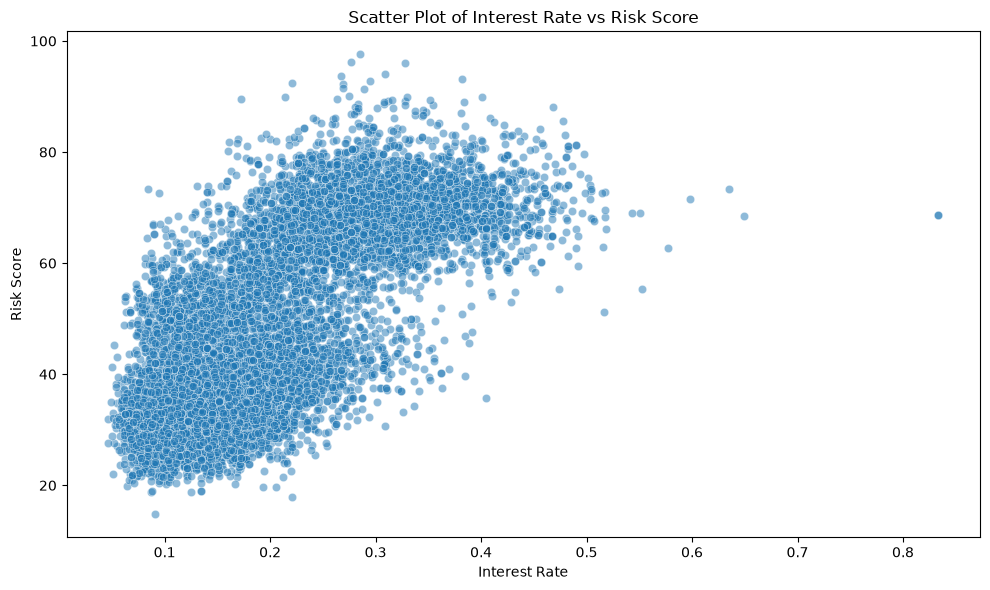

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=cropped_train, x='InterestRate', y='RiskScore', alpha=0.5)

plt.title('Scatter Plot of Interest Rate vs Risk Score')
plt.xlabel('Interest Rate')
plt.ylabel('Risk Score')
plt.tight_layout()
plt.show()

## Вывод

В исходном датасете содержится 11017 строк по 35 столбцов. В 9 столбцах пропуски в 1031 строках, у оставшихся 26 в 530 строке. Также есть 1016 полных дубликатов. Целевая переменная RiskScore имеет выбросы, не входящие в диапазон [0, 100], сама переменная, вероятно, распределена бимодально (видно на графике). Также найдены зависимости (abs(corr) > 0.7) между: Age/Experience, AnnualIncome/MonthlyIncome, AnnualIncome/RiskScore, CreditScore/BaseInterestRate, CreditScore/InterestRate, CreditScore/RiskScore, LoanAmount/MonthlyLoanPayment, TotalAssets/NetWorth, MonthlyIncome/RiskScore, BaseInterestRate/InterestRate, BaseInterestRate/RiskScore, InterestRate/RiskScore. Числовые признаки имеют разный масштаб, поэтому понадобится масштабирование признаков для правильного использования регрессии с регуляризацией. Категориальные признаки нужно будет преобразовать в числовые перед обучением. 

# Preprocessing

In [29]:
print("Source:", len(train))
print("Cropped:", len(cropped_train))

Source: 11017
Cropped: 10272


In [30]:
print("Missing values source:", cropped_train.isnull().sum().sum())
print("Duplicates source:", cropped_train.duplicated().sum())

clean_train = cropped_train.drop_duplicates()

print("Missing values cleaned:", clean_train.isnull().sum().sum())
print("Duplicates cleaned:", clean_train.duplicated().sum())

Missing values source: 4365
Duplicates source: 484
Missing values cleaned: 4104
Duplicates cleaned: 0


In [31]:
clean_train.info()

<class 'pandas.DataFrame'>
Index: 9788 entries, 0 to 9999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ApplicationDate             9788 non-null   str    
 1   Age                         9788 non-null   float64
 2   AnnualIncome                9788 non-null   float64
 3   CreditScore                 9332 non-null   float64
 4   LoanAmount                  9332 non-null   float64
 5   LoanDuration                9788 non-null   float64
 6   MaritalStatus               9788 non-null   str    
 7   NumberOfDependents          9788 non-null   float64
 8   HomeOwnershipStatus         9788 non-null   str    
 9   MonthlyDebtPayments         9332 non-null   float64
 10  CreditCardUtilizationRate   9788 non-null   float64
 11  NumberOfOpenCreditLines     9788 non-null   float64
 12  NumberOfCreditInquiries     9788 non-null   float64
 13  DebtToIncomeRatio           9788 non-null   float

# Preparing

In [32]:
X = clean_train.drop(columns=['RiskScore'])
y = clean_train['RiskScore']

X_train, X_validation, y_train, y_validation = train_test_split(X, y, test_size=0.2, random_state=42)

In [33]:
known_credit = X_train['CreditScore'].notna()

X_train = X_train.loc[known_credit].copy()
y_train = y_train.loc[known_credit].copy()

X_validation = X_validation.copy()

In [34]:
def restore_financial_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()

    monthly_rate = data['InterestRate'] / 12
    duration = data['LoanDuration']
    payment = data['MonthlyLoanPayment']

    non_zero_rate = monthly_rate.replace(0, np.nan)

    restored_loan = (payment * (-np.expm1(-duration * np.log1p(monthly_rate)))) / non_zero_rate
    restored_loan = restored_loan.where(monthly_rate.ne(0), payment * duration)
    data['LoanAmount'] = data['LoanAmount'].fillna(restored_loan)

    restored_debt = data['TotalDebtToIncomeRatio'] * data['MonthlyIncome'] - data['MonthlyLoanPayment']
    data['MonthlyDebtPayments'] = data['MonthlyDebtPayments'].fillna(restored_debt)

    return data


In [35]:
X_train_restored = restore_financial_features(X_train)
X_validation_restored = restore_financial_features(X_validation)

print("Restored LoanAmount in training set:", X_train['LoanAmount'].isnull().sum() - X_train_restored['LoanAmount'].isnull().sum())
print("Restored LoanAmount in validation set:", X_validation['LoanAmount'].isnull().sum() - X_validation_restored['LoanAmount'].isnull().sum())

Restored LoanAmount in training set: 0
Restored LoanAmount in validation set: 90


In [36]:
X_train_restored['CreditScoreWasMissing'] = X_train_restored['CreditScore'].isna().astype(float)
X_validation_restored['CreditScoreWasMissing'] = X_validation_restored['CreditScore'].isna().astype(float)

In [37]:
credit_features = [
    'InterestRate',
    'LoanAmount',
    'LoanDuration',
]

credit_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0, random_state=42)
)

credit_model.fit(X_train_restored[credit_features], X_train_restored['CreditScore'])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['InterestRate','LoanAmount','LoanDuration']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [38]:
missing_credit = X_validation_restored['CreditScore'].isna()

if missing_credit.any():
    predicted_credit = credit_model.predict(
        X_validation_restored.loc[
            missing_credit, 
            credit_features
        ]
    )

    X_validation_restored.loc[
        missing_credit, 
        'CreditScore'
    ] = np.clip(predicted_credit, 300, 850)

print("Restored CreditScore:", missing_credit.sum())
print("Missing values:", X_validation_restored['CreditScore'].isnull().sum())

Restored CreditScore: 90
Missing values: 0


In [39]:
rate_features = [
    'CreditScore',
    'LoanAmount',
    'LoanDuration',
]

known_rate = X_train_restored['BaseInterestRate'].notna()

rate_model = LinearRegression()

rate_model.fit(
    X_train_restored.loc[known_rate, rate_features],
    X_train_restored.loc[known_rate, 'BaseInterestRate']
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[-0., 0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['CreditScore','LoanAmount','LoanDuration']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.465
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [40]:
def restore_base_interest_rate(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()

    missing_rate = data['BaseInterestRate'].isna()

    if missing_rate.any():
        data.loc[missing_rate, 'BaseInterestRate'] = rate_model.predict(
            data.loc[missing_rate, rate_features]
        )

    return data

In [41]:
X_train_restored = restore_base_interest_rate(X_train_restored)
X_validation_restored = restore_base_interest_rate(X_validation_restored)

In [42]:
print(X_train_restored.isnull().sum())
print(X_validation_restored.isnull().sum())

ApplicationDate               0
Age                           0
AnnualIncome                  0
CreditScore                   0
LoanAmount                    0
LoanDuration                  0
MaritalStatus                 0
NumberOfDependents            0
HomeOwnershipStatus           0
MonthlyDebtPayments           0
CreditCardUtilizationRate     0
NumberOfOpenCreditLines       0
NumberOfCreditInquiries       0
DebtToIncomeRatio             0
BankruptcyHistory             0
LoanPurpose                   0
PreviousLoanDefaults          0
PaymentHistory                0
LengthOfCreditHistory         0
SavingsAccountBalance         0
CheckingAccountBalance        0
TotalAssets                   0
TotalLiabilities              0
MonthlyIncome                 0
UtilityBillsPaymentHistory    0
JobTenure                     0
EmploymentStatus              0
EducationLevel                0
Experience                    0
NetWorth                      0
BaseInterestRate              0
Interest

In [43]:
X_train_final = X_train_restored.copy()
X_validation_final = X_validation_restored.copy()

In [44]:
numeric_features = X_train_final.select_dtypes(include=[np.number]).columns.tolist()

train_medians = X_train_final[numeric_features].median()

X_train_final[numeric_features] = X_train_final[numeric_features].fillna(train_medians)
X_validation_final[numeric_features] = X_validation_final[numeric_features].fillna(train_medians)

In [45]:
print(X_train_final.isnull().sum())
print(X_validation_final.isnull().sum())

ApplicationDate               0
Age                           0
AnnualIncome                  0
CreditScore                   0
LoanAmount                    0
LoanDuration                  0
MaritalStatus                 0
NumberOfDependents            0
HomeOwnershipStatus           0
MonthlyDebtPayments           0
CreditCardUtilizationRate     0
NumberOfOpenCreditLines       0
NumberOfCreditInquiries       0
DebtToIncomeRatio             0
BankruptcyHistory             0
LoanPurpose                   0
PreviousLoanDefaults          0
PaymentHistory                0
LengthOfCreditHistory         0
SavingsAccountBalance         0
CheckingAccountBalance        0
TotalAssets                   0
TotalLiabilities              0
MonthlyIncome                 0
UtilityBillsPaymentHistory    0
JobTenure                     0
EmploymentStatus              0
EducationLevel                0
Experience                    0
NetWorth                      0
BaseInterestRate              0
Interest

In [46]:
loan_purpose_mode = X_train_final['LoanPurpose'].mode().iloc[0]

X_train_final['LoanPurpose'] = X_train_final['LoanPurpose'].fillna(loan_purpose_mode)
X_validation_final['LoanPurpose'] = X_validation_final['LoanPurpose'].fillna(loan_purpose_mode)

In [47]:
print(X_train_final.isnull().sum())
print(X_validation_final.isnull().sum())

ApplicationDate               0
Age                           0
AnnualIncome                  0
CreditScore                   0
LoanAmount                    0
LoanDuration                  0
MaritalStatus                 0
NumberOfDependents            0
HomeOwnershipStatus           0
MonthlyDebtPayments           0
CreditCardUtilizationRate     0
NumberOfOpenCreditLines       0
NumberOfCreditInquiries       0
DebtToIncomeRatio             0
BankruptcyHistory             0
LoanPurpose                   0
PreviousLoanDefaults          0
PaymentHistory                0
LengthOfCreditHistory         0
SavingsAccountBalance         0
CheckingAccountBalance        0
TotalAssets                   0
TotalLiabilities              0
MonthlyIncome                 0
UtilityBillsPaymentHistory    0
JobTenure                     0
EmploymentStatus              0
EducationLevel                0
Experience                    0
NetWorth                      0
BaseInterestRate              0
Interest

# Feature Engineering

In [48]:
def create_financial_features(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()

    ratio_pairs = [
        ('LoanAmount', 'AnnualIncome'),
        ('NetWorth', 'LoanAmount'),
        ('TotalLiabilities', 'TotalAssets'),
        ('MonthlyDebtPayments', 'MonthlyIncome'),
        ('MonthlyLoanPayment', 'MonthlyIncome'),
        ('SavingsAccountBalance', 'LoanAmount'),
        ('NetWorth', 'AnnualIncome'),
    ]

    money_columns = [
        'AnnualIncome',
        'MonthlyIncome',
        'LoanAmount',
        'MonthlyDebtPayments',
        'MonthlyLoanPayment',
        'SavingsAccountBalance',
        'CheckingAccountBalance',
        'TotalAssets',
        'TotalLiabilities',
        'NetWorth',
        'TotalDebtToIncomeRatio',
    ]

    boundaries = {
        'CreditScore': [300, 850],
        'MonthlyIncome': [1250, 25000],
    }

    features = {}

    for numerator, denominator in ratio_pairs:
        ratio = data[numerator] / data[denominator].replace(0, np.nan)
        features[f'{numerator}_to_{denominator}_ratio'] = np.log1p(ratio.clip(lower=0))

    result[money_columns] = np.log1p(data[money_columns].clip(lower=0))

    features.update({
        'RateSpread': data['InterestRate'] - data['BaseInterestRate'],
        'RateRatio': data['InterestRate'] / data['BaseInterestRate'],
    })

    for column, values in boundaries.items():
        for value in values:
            features[f'{column}_at_{value}'] = data[column].eq(value).astype(float)

    total_payment = data['MonthlyLoanPayment'] + data['MonthlyDebtPayments']

    credit_gap = (850 - data['CreditScore']) / 550
    log_income = np.log(data['MonthlyIncome'] / 5000)
    log_debt = np.log(data['TotalDebtToIncomeRatio'])

    features.update({
        'IncomeAboveMonthlyCap': np.log(data['AnnualIncome'] / (12 * data['MonthlyIncome'])).clip(lower=0),
        'NetWorthAdjusted': (~np.isclose(data['NetWorth'], data['TotalAssets'] - data['TotalLiabilities'])).astype(float),
        'NewPaymentShare': data['MonthlyLoanPayment'] / total_payment,
        'LogLoanIncome': np.log(data['LoanAmount'] / data['AnnualIncome']),
        'LogTotalDebt': log_debt,
        'NetCashAfterDebt': np.arcsinh((data['MonthlyIncome'] - total_payment) / 1000),
        'Credit_x_Debt': credit_gap * log_debt,
        'Credit_x_Income': credit_gap * log_income,
        'Income_x_Debt': log_income * log_debt,
        'Credit_x_Income_x_Debt': credit_gap * log_income * log_debt,
        'Credit_x_Bankruptcy': credit_gap * data['BankruptcyHistory'],
        'ShortHistory': (10 - data['LengthOfCreditHistory']).clip(lower=0),
    })

    return pd.concat([result, pd.DataFrame(features, index=data.index)], axis=1)

In [49]:
X_train_features = create_financial_features(X_train_final)
X_validation_features = create_financial_features(X_validation_final)

new_cols = [col for col in X_train_features.columns if col not in X_train_final.columns]

print(f"Added new {len(new_cols)} financial features")
X_train_features.head()

Added new 25 financial features


,ApplicationDate,Age,AnnualIncome,CreditScore,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,...,NewPaymentShare,LogLoanIncome,LogTotalDebt,NetCashAfterDebt,Credit_x_Debt,Credit_x_Income,Income_x_Debt,Credit_x_Income_x_Debt,Credit_x_Bankruptcy,ShortHistory
3646,2006-10-03,32.0,12.611541,828.0,9.110851,36.0,Married,0.0,Mortgage,6.609349,...,0.279038,-3.500797,-3.191461,3.870477,-0.127658,0.064378,-5.136459,-0.205458,0.0,6.0
522,2003-11-20,55.0,10.734264,505.0,8.188133,24.0,Single,2.0,Mortgage,7.245655,...,0.119110,-2.546387,-0.877571,1.543904,-0.550477,-0.168020,0.235064,0.147449,0.0,0.0
2645,1980-02-03,37.0,12.611541,798.0,11.085690,36.0,Widowed,3.0,Mortgage,5.552960,...,0.899220,-1.525863,-2.282744,3.804929,-0.215823,0.152165,-3.673935,-0.347354,0.0,8.0
7323,1994-01-06,38.0,11.758503,671.0,9.500843,48.0,Married,2.0,Own,6.259581,...,0.424643,-2.257727,-2.463157,2.972591,-0.801646,0.246172,-1.863122,-0.606361,0.0,5.0
6263,2008-10-08,31.0,11.253649,835.0,10.962978,36.0,Single,0.0,Own,5.837730,...,0.855582,-0.290676,-0.998873,2.109609,-0.027242,0.006860,-0.251253,-0.006852,0.0,0.0


# Edge features

In [50]:
def create_threshold_features(data: pd.DataFrame) -> pd.DataFrame:
    thresholds = {
        'CreditScore': [500, 550, 600, 650, 700, 750, 800],
        'AnnualIncome': [30000, 40000, 50000, 60000, 80000, 100000, 150000],
        'DebtToIncomeRatio': [0.2, 0.3, 0.35, 0.4, 0.5],
        'TotalDebtToIncomeRatio': [0.2, 0.3, 0.4, 0.5, 1.0],
        'LengthOfCreditHistory': [3, 5, 7, 10, 15],
        'NetWorth': [10000, 50000, 100000, 250000],
        'BankruptcyHistory': [0.5],
        'PreviousLoanDefaults': [0.5],
    }

    features = {}
    source_columns = {}

    for column, values in thresholds.items():
        for value in values:
            name = f'{column}_bigger_{value}'
            features[name] = data[column].ge(value).astype(float)
            source_columns[name] = column

    for left, right in combinations(list(features), 2):
        if source_columns[left] != source_columns[right]:
            features[f'{left}_and_{right}'] = (features[left] * features[right])

    extra_thresholds = {
        'Income': (data['AnnualIncome'], [45000, 50000, 110000, 120000, 125000]),
        'LoanIncome': (data['LoanAmount'] / data['AnnualIncome'], [0.35, 0.4, 0.45]),
        'TotalDebt': (data['TotalDebtToIncomeRatio'], [0.13, 0.15, 0.17, 0.20, 0.23]),
        'Utilization': (data['CreditCardUtilizationRate'], [0.20]),
    }

    for name, (values, bounds) in extra_thresholds.items():
        for bound in bounds:
            features[f'Extra_{name}_ge_{bound}'] = values.ge(bound).astype(float)

    return pd.DataFrame(features, index=data.index)

In [51]:
train_thresholds = create_threshold_features(X_train_final)
validation_thresholds = create_threshold_features(X_validation_final)

print("Edge features:", train_thresholds.shape[1])
train_thresholds.head()

Edge features: 566


,CreditScore_bigger_500,CreditScore_bigger_550,CreditScore_bigger_600,CreditScore_bigger_650,CreditScore_bigger_700,CreditScore_bigger_750,CreditScore_bigger_800,AnnualIncome_bigger_30000,AnnualIncome_bigger_40000,AnnualIncome_bigger_50000,...,Extra_Income_ge_125000,Extra_LoanIncome_ge_0.35,Extra_LoanIncome_ge_0.4,Extra_LoanIncome_ge_0.45,Extra_TotalDebt_ge_0.13,Extra_TotalDebt_ge_0.15,Extra_TotalDebt_ge_0.17,Extra_TotalDebt_ge_0.2,Extra_TotalDebt_ge_0.23,Extra_Utilization_ge_0.2
3646,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
522,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0
2645,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7323,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6263,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0


In [52]:
X_train_edged = pd.concat([X_train_features, train_thresholds], axis=1)
X_validation_edged = pd.concat([X_validation_features, validation_thresholds], axis=1)

print(X_train_edged.info())
print(X_validation_edged.info())

<class 'pandas.DataFrame'>
Index: 7464 entries, 3646 to 7434
Columns: 626 entries, ApplicationDate to Extra_Utilization_ge_0.2
dtypes: float64(620), str(6)
memory usage: 35.7 MB
None
<class 'pandas.DataFrame'>
Index: 1958 entries, 9806 to 3879
Columns: 626 entries, ApplicationDate to Extra_Utilization_ge_0.2
dtypes: float64(620), str(6)
memory usage: 9.4 MB
None


# Preparing

In [53]:
X_train_model = X_train_edged.drop(columns=['ID', 'ApplicationDate'], errors='ignore').copy()
X_validation_model = X_validation_edged.drop(columns=['ID', 'ApplicationDate'], errors='ignore').copy()

In [54]:
numeric_columns = X_train_model.select_dtypes(include=np.number).columns.to_list()
categorical_columns = [col for col in X_train_model.columns if col not in numeric_columns]

print(numeric_columns)
print(categorical_columns)

['Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanDuration', 'NumberOfDependents', 'MonthlyDebtPayments', 'CreditCardUtilizationRate', 'NumberOfOpenCreditLines', 'NumberOfCreditInquiries', 'DebtToIncomeRatio', 'BankruptcyHistory', 'PreviousLoanDefaults', 'PaymentHistory', 'LengthOfCreditHistory', 'SavingsAccountBalance', 'CheckingAccountBalance', 'TotalAssets', 'TotalLiabilities', 'MonthlyIncome', 'UtilityBillsPaymentHistory', 'JobTenure', 'Experience', 'NetWorth', 'BaseInterestRate', 'InterestRate', 'MonthlyLoanPayment', 'TotalDebtToIncomeRatio', 'CreditScoreWasMissing', 'LoanAmount_to_AnnualIncome_ratio', 'NetWorth_to_LoanAmount_ratio', 'TotalLiabilities_to_TotalAssets_ratio', 'MonthlyDebtPayments_to_MonthlyIncome_ratio', 'MonthlyLoanPayment_to_MonthlyIncome_ratio', 'SavingsAccountBalance_to_LoanAmount_ratio', 'NetWorth_to_AnnualIncome_ratio', 'RateSpread', 'RateRatio', 'CreditScore_at_300', 'CreditScore_at_850', 'MonthlyIncome_at_1250', 'MonthlyIncome_at_25000', 'IncomeAbove

In [55]:
from sklearn.preprocessing import SplineTransformer

continuous_columns = [
    column for column in numeric_columns
    if X_train_model[column].nunique() > 15
]

other_numeric_columns = [
    column for column in numeric_columns
    if column not in continuous_columns
]

spline_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('splines', SplineTransformer(
        n_knots=8,
        degree=3,
        knots='uniform',
        include_bias=False
    ))
])

preprocessor = ColumnTransformer([
    (
        'continuous',
        spline_transformer,
        continuous_columns
    ),
    (
        'other_numeric',
        SimpleImputer(strategy='median'),
        other_numeric_columns
    ),
    (
        'categorical',
        OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ),
        categorical_columns
    )
])

print('Spline:', len(continuous_columns))
print('Numeric:', len(other_numeric_columns))

Spline: 41
Numeric: 579


# Lasso regression

In [56]:
lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('regression', Lasso(
        alpha=0.03,
        max_iter=18000,
        tol=3e-4
    ))
])

lasso_model.fit(X_train_model, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](625,)","['Age','AnnualIncome','CreditScore',...,'Extra_TotalDebt_ge_0.2', 'Extra_TotalDebt_ge_0.23','Extra_Utilization_ge_0.2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,625
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('continuous', ...), ('other_numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the da

In [57]:
train_prediction = lasso_model.predict(X_train_model)
validation_prediction = lasso_model.predict(X_validation_model)

results = []

for name, actual, predicted in [('Train', y_train, train_prediction), ('Validation', y_validation, validation_prediction)]:
    results.append({
        'Dataset': name,
        'MSE': mean_squared_error(actual, predicted),
        'MAE': mean_absolute_error(actual, predicted),
        'R2': r2_score(actual, predicted)
    })

results = pd.DataFrame(results)
results

,Dataset,MSE,MAE,R2
0,Train,19.801695,3.262137,0.932970
1,Validation,24.395003,3.541203,0.919762


In [58]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_mse = -cross_val_score(
    clone(lasso_model),
    X_train_model,
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

display(pd.DataFrame({
    'Fold': range(1, 6),
    'MSE': cv_mse
}))

print(f'CV MSE: {cv_mse.mean()}')
print(f'Standard dispersion: {cv_mse.std()}')

,Fold,MSE
0,1,22.743880
1,2,22.770370
2,3,21.091931
3,4,20.995410
4,5,21.335782


CV MSE: 21.787474469421785
Standard dispersion: 0.7994957911319766


In [59]:
known_credit = X_validation['CreditScore'].notna()

complete_validation_mse = mean_squared_error(
    y_validation.loc[known_credit],
    validation_prediction[known_credit.to_numpy()]
)

print(f'Validation MSE without restoring CreditScore:', complete_validation_mse)

Validation MSE without restoring CreditScore: 22.94756869889469


# Hypothesis

Так как в MSE < 18 я не знаю как можно попасть даже с sklearn, я решил посмотреть что можно сделать. В инете есть датасет, похожий на наш, но там есть еще признак LoanApproved, с помощью которого видимо и создается, веротно, бимодальное распределение RiskScore, а также другие вспомогательные признаки. Далее я проверю подойдет ли подобная идея в нашей ситуации, сгенерировав новые признаки и примерно подобрав генератор.

In [60]:
def create_hypothesis_features(data: pd.DataFrame) -> pd.DataFrame:
    def tier(column, boundaries):
        return np.searchsorted(
            boundaries,
            data[column].to_numpy(),
            side='right'
        )

    month = pd.to_datetime(data['ApplicationDate']).dt.month
    season = month.between(3, 8).astype(float)

    wealth = (
        data['TotalAssets'] - data['TotalLiabilities']
    ).clip(lower=1000)

    education = data['EducationLevel'].map({
        'High School': 0.2,
        'Associate': 0.1,
        'Bachelor': 0.0,
        'Master': -0.1,
        'Doctorate': -0.2
    }).fillna(0)

    margin = (
        (data['CreditScore'] - 600) / 250
        + 1 - 12 * data['MonthlyIncome'] / 100000
        + 2 * (data['TotalDebtToIncomeRatio'] - 0.4)
        + (data['LoanAmount'] - 10000) / 90000
        + 10 * (data['InterestRate'] - 0.05)
        + 0.5 * data['BankruptcyHistory']
        + 0.3 * data['PreviousLoanDefaults']
        + 0.2 * data['EmploymentStatus'].eq('Unemployed')
        - 0.1 * data['HomeOwnershipStatus'].isin(['Own', 'Mortgage'])
        - data['PaymentHistory'] / 120
        - data['LengthOfCreditHistory'] / 60
        - wealth / 500000
        + (data['Age'] - 40).abs() / 100
        - data['Experience'] / 200
        + education
        - 0.1 * season
    )

    components = pd.DataFrame({
        'Credit': 3 * (
            5 - tier('CreditScore', [600, 650, 700, 750])
        ),
        'Debt': 2 * (
            1 + tier('DebtToIncomeRatio', [0.2, 0.3, 0.4, 0.5])
        ),
        'Payments': 2 * (
            5 - tier('PaymentHistory', [90, 95, 97, 99])
        ),
        'Bankruptcy': 3 * (1 + 4 * data['BankruptcyHistory']),
        'Defaults': 3 * (1 + 2 * data['PreviousLoanDefaults']),
        'Utilization': 1 + tier(
            'CreditCardUtilizationRate', [0.2, 0.4, 0.6, 0.8]
        ),
        'History': 5 - tier(
            'LengthOfCreditHistory', [3, 5, 7, 10]
        ),
        'Income': 5 - tier(
            'AnnualIncome', [30000, 50000, 80000, 120000]
        ),
        'Employment': data['EmploymentStatus'].map({
            'Employed': 1,
            'Part-time': 3
        }).fillna(4),
        'Wealth': 2 * (
            5 - tier('NetWorth', [50000, 100000, 250000, 500000])
        )
    }, index=data.index)

    base = components.sum(axis=1)
    narrow_gate = ndtr((1 - margin) / 0.1)
    soft_gate = ndtr((1 - margin) / 0.2)

    features = {
        'Margin': np.arcsinh(margin),
        'Base': base,
        'Expected': base * (1 - 0.2 * narrow_gate)
    }

    for boundary in [0.7, 1.0, 1.3]:
        for width in [0.1, 0.25]:
            gate = ndtr((boundary - margin) / width)
            name = f'Narrow_{boundary}_{width}'

            features[name] = gate
            features[f'{name}_x_Base'] = gate * base

    for column in components:
        values = components[column]

        features[f'Component_{column}'] = values
        features[f'Component_{column}_x_Narrow'] = values * narrow_gate
        features[f'Component_{column}_x_Soft'] = values * soft_gate

    for boundary in [0.85, 1.0, 1.15]:
        for width in [0.35, 0.47, 0.60, 0.8]:
            gate = ndtr((boundary - margin) / width)
            name = f'Wide_{boundary}_{width}'

            features[name] = gate
            features[f'{name}_x_Base'] = gate * base

    wide_gate = ndtr((1 - margin) / 0.47)
    near_boundary = np.exp(
        -0.5 * ((margin - 1) / 0.48) ** 2
    )

    for column in components:
        values = components[column]

        features[f'Component_{column}_x_Wide'] = values * wide_gate
        features[f'Component_{column}_x_Near'] = values * near_boundary

    liquid_assets = (
        data['SavingsAccountBalance'] + data['CheckingAccountBalance']
    )

    total_payment = (
        data['MonthlyLoanPayment'] + data['MonthlyDebtPayments']
    )

    liquidity = {
        'LiquidAssets': np.log1p(liquid_assets),
        'LiquidToPayments': np.log1p(liquid_assets / total_payment),
        'LiquidToIncome': np.log1p(liquid_assets / data['MonthlyIncome']),
        'LiquidToLoan': np.log1p(liquid_assets / data['LoanAmount']),
        'LiquidToAssets': np.log1p(liquid_assets / data['TotalAssets'])
    }

    for name, values in liquidity.items():
        features[name] = values
        features[f'{name}_x_Near'] = values * near_boundary

    return pd.DataFrame(features, index=data.index).add_prefix('Hyp_')

In [61]:
train_hypothesis = create_hypothesis_features(X_train_final)

validation_hypothesis = create_hypothesis_features(
    X_validation_final
)

print('Hypothesis features:', train_hypothesis.shape[1])
display(train_hypothesis.head())

Hypothesis features: 99


,Hyp_Margin,Hyp_Base,Hyp_Expected,Hyp_Narrow_0.7_0.1,Hyp_Narrow_0.7_0.1_x_Base,Hyp_Narrow_0.7_0.25,Hyp_Narrow_0.7_0.25_x_Base,Hyp_Narrow_1.0_0.1,Hyp_Narrow_1.0_0.1_x_Base,Hyp_Narrow_1.0_0.25,...,Hyp_LiquidAssets,Hyp_LiquidAssets_x_Near,Hyp_LiquidToPayments,Hyp_LiquidToPayments_x_Near,Hyp_LiquidToIncome,Hyp_LiquidToIncome_x_Near,Hyp_LiquidToLoan,Hyp_LiquidToLoan_x_Near,Hyp_LiquidToAssets,Hyp_LiquidToAssets_x_Near
3646,-1.880283,34.0,27.200000,1.000000e+00,3.400000e+01,1.000000e+00,3.400000e+01,1.000000e+00,3.400000e+01,1.000000e+00,...,8.531293,1.970368e-16,1.780513,4.112231e-17,0.184652,4.264684e-18,0.444748,1.027180e-17,0.006068,1.401336e-19
522,1.091479,52.0,51.993212,2.569797e-10,1.336294e-08,6.460981e-03,3.359710e-01,6.527180e-04,3.394134e-02,9.923675e-02,...,7.971776,6.370177e+00,1.037273,8.288758e-01,0.563818,4.505420e-01,0.590779,4.720860e-01,0.116129,9.279740e-02
2645,-0.344721,39.0,31.200000,1.000000e+00,3.900000e+01,9.999870e-01,3.899949e+01,1.000000e+00,3.900000e+01,1.000000e+00,...,8.446556,1.603118e-01,1.039073,1.972114e-02,0.170856,3.242771e-03,0.068974,1.309104e-03,0.176624,3.352235e-03
7323,0.137526,53.0,42.400000,1.000000e+00,5.300000e+01,9.877170e-01,5.234900e+01,1.000000e+00,5.300000e+01,9.997178e-01,...,8.856234,1.765553e+00,2.167253,4.320571e-01,0.506030,1.008806e-01,0.421884,8.410556e-02,0.118731,2.366982e-02
6263,1.605939,39.0,39.000000,1.925497e-64,7.509437e-63,6.727076e-12,2.623560e-10,2.786150e-44,1.086599e-42,1.320814e-08,...,10.027871,1.506056e-01,2.357419,3.540538e-02,1.509007,2.266334e-02,0.331125,4.973064e-03,0.693147,1.041017e-02


In [62]:
X_train_model = pd.concat(
    [X_train_edged, train_hypothesis],
    axis=1
).drop(
    columns=['ID', 'ApplicationDate'],
    errors='ignore'
)

X_validation_model = pd.concat(
    [X_validation_edged, validation_hypothesis],
    axis=1
).drop(
    columns=['ID', 'ApplicationDate'],
    errors='ignore'
)

In [63]:
hypothesis_columns = train_hypothesis.columns.tolist()

base_columns = [
    column for column in X_train_model.columns
    if column not in hypothesis_columns
]

numeric_columns = (
    X_train_model[base_columns]
    .select_dtypes(include=np.number)
    .columns
    .tolist()
)

categorical_columns = [
    column for column in base_columns
    if column not in numeric_columns
]

In [64]:
combined_preprocessor = ColumnTransformer(
    transformers=[
        (
            'base',
            Pipeline([
                ('features', preprocessor),
                ('scaler', StandardScaler())
            ]),
            base_columns
        ),
        (
            'hypothesis',
            Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]),
            hypothesis_columns
        )
    ],
    transformer_weights={
        'base': 1.0,
        'hypothesis': 4.0
    }
)

lasso_model = Pipeline([
    ('preprocessor', combined_preprocessor),
    ('regression', Lasso(
        alpha=0.10,
        max_iter=18000,
        tol=3e-4
    ))
])

lasso_model.fit(X_train_model, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](724,)","['Age','AnnualIncome','CreditScore',...,'Hyp_LiquidToLoan_x_Near', 'Hyp_LiquidToAssets','Hyp_LiquidToAssets_x_Near']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,724
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('base', ...), ('hypothesis', ...)]"
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.","{'base': 1.0, 'hypothesis': 4.0}"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformer

In [65]:
train_prediction = lasso_model.predict(X_train_model)
validation_prediction = lasso_model.predict(X_validation_model)

results = []

for name, actual, predicted in [('Train', y_train, train_prediction), ('Validation', y_validation, validation_prediction)]:
    results.append({
        'Dataset': name,
        'MSE': mean_squared_error(actual, predicted),
        'MAE': mean_absolute_error(actual, predicted),
        'R2': r2_score(actual, predicted)
    })

results = pd.DataFrame(results)
results

,Dataset,MSE,MAE,R2
0,Train,17.650499,2.913034,0.940252
1,Validation,19.916234,3.052532,0.934494


In [66]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_mse = -cross_val_score(
    clone(lasso_model),
    X_train_model,
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

display(pd.DataFrame({
    'Fold': range(1, 6),
    'MSE': cv_mse
}))

print(f'CV MSE: {cv_mse.mean()}')
print(f'Standard dispersion: {cv_mse.std()}')

,Fold,MSE
0,1,19.752611
1,2,19.012932
2,3,16.021973
3,4,16.088659
4,5,18.557392


CV MSE: 17.88671341336165
Standard dispersion: 1.5433737057232095


## Вывод
Гипотеза верна, MSE упал с 21.79 до 17.89. Далее буду реализовывать уже свои модели, скейлеры и т.п.

# My implementation

In [67]:
class MyZScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)

        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1

        return self
    
    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.std_
    
    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [68]:
class MyMinMaxScaler:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        self.range_ = X.max(axis=0) - self.min_
        self.range_[self.range_ == 0] = 1
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [69]:
scaler_train = np.array([
    [1.0, 10.0, 7.0],
    [2.0, 30.0, 7.0],
    [5.0, 50.0, 7.0]
])

scaler_validation = np.array([
    [0.0, 20.0, 7.0],
    [6.0, 60.0, 7.0]
])

scaler_results = []

for name, own_class, reference_class in [
    ('Z-score', MyZScaler, StandardScaler),
    ('Min-max', MyMinMaxScaler, MinMaxScaler)
]:
    own = own_class().fit(scaler_train)
    reference = reference_class().fit(scaler_train)

    own_result = own.transform(scaler_validation)
    reference_result = reference.transform(scaler_validation)

    np.testing.assert_allclose(
        own_result,
        reference_result,
        atol=1e-12
    )

    scaler_results.append({
        'Scaler': name,
        'Maximum difference': np.max(
            np.abs(own_result - reference_result)
        )
    })

scaler_results

[{'Scaler': 'Z-score', 'Maximum difference': np.float64(0.0)},
 {'Scaler': 'Min-max', 'Maximum difference': np.float64(0.0)}]

In [70]:
def metric_array_validation(y, pred):
    y = np.asarray(y, dtype=float).reshape(-1)
    pred = np.asarray(pred, dtype=float).reshape(-1)

    if y.shape != pred.shape or y.size == 0:
        raise ValueError("incorrect metric array sizes")
    
    return y, pred

In [71]:
def my_mse(y, pred):
    y, pred = metric_array_validation(y, pred)
    
    return np.mean((y - pred) ** 2)

In [72]:
def my_mae(y, pred):
    y, pred = metric_array_validation(y, pred)
    
    return np.mean(np.abs(y - pred))

In [73]:
def my_r2(y, pred):
    y, pred = metric_array_validation(y, pred)

    if len(y) < 2:
        return np.nan
    
    residual = np.sum((y - pred) ** 2)
    total = np.sum((y - y.mean()) ** 2)

    if total == 0:
        return residual == 0
    
    return 1 - residual / total

In [74]:
def my_mape(y, pred):
    y, pred = metric_array_validation(y, pred)
    denom = np.maximum(np.abs(y), np.finfo(float).eps)

    return np.mean(np.abs(y - pred) / denom)

In [75]:
metric_functions = {
    "MSE": (my_mse, mean_squared_error),
    "MAE": (my_mae, mean_absolute_error),
    "R2": (my_r2, r2_score),
    "MAPE": (my_mape, mean_absolute_percentage_error)
}

metric_cases = {
    "Regular values": (
        np.array([10.0, 20.0, 30.0, 40.0]),
        np.array([12.0, 18.0, 33.0, 39.0])
    ),
    "Perfect prediction": (
        np.array([10.0, 20.0, 30.0]),
        np.array([10.0, 20.0, 30.0])
    ),
    "Constant target": (
        np.array([5.0, 5.0, 5.0]),
        np.array([4.0, 5.0, 6.0])
    ),
    "Zero target": (
        np.array([0.0, 10.0, 20.0]),
        np.array([1.0, 12.0, 18.0])
    )
}

metric_results = []

for case_name, (actual, predicted) in metric_cases.items():
    for metric_name, (own_function, sklearn_function) in metric_functions.items():
        own_value = own_function(actual, predicted)
        sklearn_value = sklearn_function(actual, predicted)

        np.testing.assert_allclose(
            own_value,
            sklearn_value,
            rtol=1e-10,
            atol=1e-10
        )

        metric_results.append({
            "Case": case_name,
            "Metric": metric_name,
            "Custom": own_value,
            "Sklearn": sklearn_value
        })

metric_results

[{'Case': 'Regular values',
  'Metric': 'MSE',
  'Custom': np.float64(4.5),
  'Sklearn': 4.5},
 {'Case': 'Regular values',
  'Metric': 'MAE',
  'Custom': np.float64(2.0),
  'Sklearn': 2.0},
 {'Case': 'Regular values',
  'Metric': 'R2',
  'Custom': np.float64(0.964),
  'Sklearn': 0.964},
 {'Case': 'Regular values',
  'Metric': 'MAPE',
  'Custom': np.float64(0.10625000000000001),
  'Sklearn': 0.10625000000000001},
 {'Case': 'Perfect prediction',
  'Metric': 'MSE',
  'Custom': np.float64(0.0),
  'Sklearn': 0.0},
 {'Case': 'Perfect prediction',
  'Metric': 'MAE',
  'Custom': np.float64(0.0),
  'Sklearn': 0.0},
 {'Case': 'Perfect prediction',
  'Metric': 'R2',
  'Custom': np.float64(1.0),
  'Sklearn': 1.0},
 {'Case': 'Perfect prediction',
  'Metric': 'MAPE',
  'Custom': np.float64(0.0),
  'Sklearn': 0.0},
 {'Case': 'Constant target',
  'Metric': 'MSE',
  'Custom': np.float64(0.6666666666666666),
  'Sklearn': 0.6666666666666666},
 {'Case': 'Constant target',
  'Metric': 'MAE',
  'Custom': np

In [76]:
class MyLinearRegression:
    def __init__(self, method='analytic', lr=0.01, epochs=1000,
                 random_state=42, alpha=0.0, penalty='l2',
                 l1_ratio=0.5, p=3):
        self.method = method
        self.lr = lr
        self.epochs = epochs
        self.random_state = random_state
        self.alpha = alpha
        self.penalty = penalty
        self.l1_ratio = l1_ratio
        self.p = p

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        X_mean = X.mean(axis=0)
        y_mean = y.mean()

        X = X - X_mean
        y = y - y_mean

        l1 = 0.0
        l2 = 0.0

        if self.penalty == 'l1':
            l1 = self.alpha
        elif self.penalty == 'l2':
            l2 = self.alpha
        elif self.penalty == 'elastic':
            l1 = self.alpha * self.l1_ratio
            l2 = self.alpha * (1 - self.l1_ratio)
        elif self.penalty == 'lp':
            if self.p < 1:
                raise ValueError('p must be at least 1')
            if self.p == 1:
                l1 = self.alpha
            elif self.p == 2:
                l2 = self.alpha

        general_lp = self.penalty == 'lp' and self.p > 2
        fractional_lp = self.penalty == 'lp' and 1 < self.p < 2

        self.loss_history_ = []

        if self.method == 'analytic':
            if self.alpha > 0 and (l1 > 0 or general_lp or fractional_lp):
                raise ValueError('Use gd or sgd for this penalty')

            X_extended = np.vstack([X, np.sqrt(len(y) * l2) * np.eye(X.shape[1])])
            y_extended = np.concatenate([y, np.zeros(X.shape[1])])

            self.coef_ = np.linalg.lstsq(X_extended, y_extended, rcond=None)[0]

        else:
            self.coef_ = np.zeros(X.shape[1])
            rng = np.random.default_rng(self.random_state)

            def update(gradient, step):
                gradient = gradient + l2 * self.coef_

                if general_lp or fractional_lp:
                    gradient += self.alpha * np.sign(self.coef_) * np.abs(self.coef_) ** (self.p - 1)

                weights = self.coef_ - step * gradient

                self.coef_ = np.sign(weights) * np.maximum(np.abs(weights) - step * l1, 0)

            for epoch in range(self.epochs):
                if self.method == 'gd':
                    error = X @ self.coef_ - y
                    gradient = X.T @ error / len(y)
                    update(gradient, self.lr)

                elif self.method == 'sgd':
                    step = self.lr / np.sqrt(epoch + 1)

                    for i in rng.permutation(len(y)):
                        error = X[i] @ self.coef_ - y[i]
                        update(X[i] * error, step)

                self.loss_history_.append(np.mean((X @ self.coef_ - y) ** 2))

        self.intercept_ = y_mean - X_mean @ self.coef_
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

In [77]:
rng = np.random.default_rng(42)

X_check = rng.normal(size=(120, 5))
y_check = 3 + X_check @ np.array([2, -1, 0, 0.5, 1]) + rng.normal(0, 0.05, 120)

alpha = 0.1

reference_models = {
    'l1': Lasso(alpha=alpha, tol=1e-10),
    'l2': Ridge(alpha=len(y_check) * alpha),
    'elastic': ElasticNet(
        alpha=alpha,
        l1_ratio=0.5,
        tol=1e-10
    )
}

regularization_results = []

for penalty, reference in reference_models.items():
    custom = MyLinearRegression(
        method='gd',
        penalty=penalty,
        alpha=alpha,
        lr=0.01,
        epochs=5000
    )

    custom.fit(X_check, y_check)
    reference.fit(X_check, y_check)

    custom_prediction = custom.predict(X_check)
    reference_prediction = reference.predict(X_check)

    np.testing.assert_allclose(
        custom_prediction,
        reference_prediction,
        rtol=0,
        atol=1e-5
    )

    regularization_results.append({
        'Penalty': penalty,
        'Custom MSE': my_mse(y_check, custom_prediction),
        'Sklearn MSE': my_mse(y_check, reference_prediction),
        'Max prediction difference': np.max(
            np.abs(custom_prediction - reference_prediction)
        )
    })

regularization_results

[{'Penalty': 'l1',
  'Custom MSE': np.float64(0.054685654475274355),
  'Sklearn MSE': np.float64(0.054685654474107476),
  'Max prediction difference': np.float64(8.714806654097629e-12)},
 {'Penalty': 'l2',
  'Custom MSE': np.float64(0.06906555746515837),
  'Sklearn MSE': np.float64(0.06906555746515092),
  'Max prediction difference': np.float64(4.796163466380676e-14)},
 {'Penalty': 'elastic',
  'Custom MSE': np.float64(0.05941410839631086),
  'Sklearn MSE': np.float64(0.059414108395150184),
  'Max prediction difference': np.float64(9.00257646208047e-12)}]

In [78]:
lp_model = MyLinearRegression(
    method='gd',
    penalty='lp',
    p=3,
    alpha=0.1,
    lr=0.01,
    epochs=5000
).fit(X_check, y_check)

X_centered = X_check - X_check.mean(axis=0)
error = lp_model.predict(X_check) - y_check

gradient = (
    X_centered.T @ error / len(y_check)
    + lp_model.alpha
    * np.sign(lp_model.coef_)
    * np.abs(lp_model.coef_) ** (lp_model.p - 1)
)

np.testing.assert_allclose(gradient, 0, atol=1e-6)

print('MSE:', my_mse(y_check, lp_model.predict(X_check)))

MSE: 0.11777932464740856


In [79]:
def my_kfold(X, n_splits=5, shuffle=True, random_state=42):
    indices = np.arange(len(X))

    if shuffle:
        rng = np.random.default_rng(random_state)
        rng.shuffle(indices)

    folds = np.array_split(indices, n_splits)

    for i in range(n_splits):
        validation_indices = folds[i]
        train_indices = np.concatenate([folds[j] for j in range(n_splits) if j != i])

        yield train_indices, validation_indices


def my_leave_one_out(X):
    indices = np.arange(len(X))

    for i in indices:
        train_indices = indices[indices != i]
        validation_indices = np.array([i])

        yield train_indices, validation_indices

def my_cross_validate(model_factory, X, y, splits):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    results = []

    for fold, (train_indices, validation_indices) in enumerate(splits, start=1):
        scaler = MyZScaler()

        X_train_fold = scaler.fit_transform(X[train_indices])
        X_validation_fold = scaler.transform(X[validation_indices])

        model = model_factory()
        model.fit(X_train_fold, y[train_indices])

        prediction = model.predict(X_validation_fold)

        results.append({
            'Fold': fold,
            'MSE': my_mse(y[validation_indices], prediction),
            'MAE': my_mae(y[validation_indices], prediction)
        })

    return pd.DataFrame(results)

In [80]:
rng = np.random.default_rng(42)

X_cv_check = rng.normal(size=(30, 4))
y_cv_check = 2 + X_cv_check @ np.array([1.5, -2, 0.5, 3]) + rng.normal(0, 0.1, 30)

split_checks = {
    'K-fold': (
        list(my_kfold(X_cv_check, n_splits=5, shuffle=False)),
        list(KFold(n_splits=5).split(X_cv_check))
    ),
    'Leave-one-out': (
        list(my_leave_one_out(X_cv_check)),
        list(LeaveOneOut().split(X_cv_check))
    )
}

cv_check_results = []

for name, (custom_splits, reference_splits) in split_checks.items():
    assert len(custom_splits) == len(reference_splits)

    for custom_split, reference_split in zip(custom_splits, reference_splits):
        np.testing.assert_array_equal(custom_split[0], reference_split[0])
        np.testing.assert_array_equal(custom_split[1], reference_split[1])

    custom_scores = my_cross_validate(
        lambda: MyLinearRegression(method='analytic'),
        X_cv_check,
        y_cv_check,
        custom_splits
    )

    reference_scores = -cross_val_score(
        make_pipeline(StandardScaler(), LinearRegression()),
        X_cv_check,
        y_cv_check,
        cv=reference_splits,
        scoring='neg_mean_squared_error'
    )

    np.testing.assert_allclose(
        custom_scores['MSE'],
        reference_scores,
        rtol=1e-6,
        atol=1e-10
    )

    cv_check_results.append({
        'Method': name,
        'Custom MSE': custom_scores['MSE'].mean(),
        'Sklearn MSE': reference_scores.mean()
    })


cv_check_results

[{'Method': 'K-fold',
  'Custom MSE': np.float64(0.014908346108125595),
  'Sklearn MSE': np.float64(0.014908346108125525)},
 {'Method': 'Leave-one-out',
  'Custom MSE': np.float64(0.014913549698073823),
  'Sklearn MSE': np.float64(0.014913549698073606)}]

In [81]:
rng = np.random.default_rng(42)

X_comparison = rng.normal(size=(120, 5))
y_comparison = 3 + X_comparison @ np.array([2, -1, 0, 0.5, 1]) + rng.normal(0, 0.05, 120)

reference = LinearRegression().fit(X_comparison, y_comparison)
reference_prediction = reference.predict(X_comparison)

comparison_results = []

for method in ['analytic', 'gd', 'sgd']:
    model = MyLinearRegression(
        method=method,
        alpha=0,
        lr=0.03,
        epochs=1500
    ).fit(X_comparison, y_comparison)

    prediction = model.predict(X_comparison)

    np.testing.assert_allclose(
        prediction,
        reference_prediction,
        rtol=0,
        atol=1e-3
    )

    comparison_results.append({
        'Method': method,
        'Custom MSE': my_mse(y_comparison, prediction),
        'Sklearn MSE': my_mse(y_comparison, reference_prediction),
        'Max prediction difference': np.max(np.abs(prediction - reference_prediction))
    })

comparison_results

[{'Method': 'analytic',
  'Custom MSE': np.float64(0.0024755107261289324),
  'Sklearn MSE': np.float64(0.0024755107261289397),
  'Max prediction difference': np.float64(2.6645352591003757e-15)},
 {'Method': 'gd',
  'Custom MSE': np.float64(0.002475510726128932),
  'Sklearn MSE': np.float64(0.0024755107261289397),
  'Max prediction difference': np.float64(3.909761403519951e-12)},
 {'Method': 'sgd',
  'Custom MSE': np.float64(0.0024755154031432924),
  'Sklearn MSE': np.float64(0.0024755107261289397),
  'Max prediction difference': np.float64(0.00022731111908447232)}]